# Time series and joining data — Code-Along Template

**Type into this notebook during class.** The explanation is here; the code is not.

| | |
|---|---|
| **Follow along** | Write the code in each `# TODO` cell. The hint names the functions and arguments. |
| **If you fall behind** | Do not copy frantically. Skip to the next **CHECKPOINT**, run it, rejoin. |
| **If a cell errors** | Later cells depend on it and will fail too. Run the next CHECKPOINT rather than debugging under time pressure. |
| **After class** | The worked version is `D013_07d_Pandas_TimeSeries.ipynb`. Compare, do not copy. |

Cells that are already filled in are deliberate — imports and quick glances at the
data cost class time and teach nothing.

# Module 07d: Pandas Time Series Analysis

## Why Time Series?

Time series data is everywhere in the real world:
- **Finance**: Stock prices, cryptocurrency values, trading volumes
- **Retail**: Daily sales, seasonal demand patterns
- **Weather**: Temperature, rainfall, humidity over time
- **IoT/Sensors**: Equipment readings, energy consumption
- **Healthcare**: Patient vitals, disease spread tracking
- **Web Analytics**: Website traffic, user engagement metrics

Pandas provides **powerful tools** specifically designed for time series data, making operations like:
- Parsing dates and times from strings
- Resampling data (daily → weekly, hourly → daily)
- Handling missing time periods
- Computing rolling statistics (moving averages)
- Time-based indexing and slicing

...incredibly easy!

---

## What You'll Learn

| Section | Topic | Duration |
|---------|-------|----------|
| 1 | [DateTime Basics](#1.-DateTime-Basics) | 20 min |
| 2 | [Creating Time Series Data](#2.-Creating-Time-Series-Data) | 25 min |
| 3 | [Time-Based Indexing & Selection](#3.-Time-Based-Indexing-and-Selection) | 20 min |
| 4 | [Resampling & Frequency Conversion](#4.-Resampling-and-Frequency-Conversion) | 30 min |
| 5 | [Rolling Windows & Moving Statistics](#5.-Rolling-Windows-and-Moving-Statistics) | 25 min |
| 6 | [Handling Missing Data in Time Series](#6.-Handling-Missing-Data-in-Time-Series) | 20 min |
| 7 | [Time Zones](#7.-Time-Zones) | 15 min |
| 8 | [Case Study: E-Commerce Analytics](#8.-Case-Study-E-Commerce-Analytics) | 30 min |
| 9 | [Live Exercises with Solutions](#9.-Live-Exercises-with-Solutions) | 35 min |

**Total Estimated Time: ~3.5 hours**

---

## Setup

In [ ]:
# TODO: call `warnings.filterwarnings`
# Hint: warnings.filterwarnings, pd.set_option, plt.style.use

---

# 1. DateTime Basics

Before diving into time series analysis, we need to understand how Pandas handles dates and times.

## Key DateTime Types in Pandas

| Type | Description | Example |
|------|-------------|--------|
| `Timestamp` | Single moment in time | `2024-01-15 09:30:00` |
| `DatetimeIndex` | Index of Timestamps | Index for time series |
| `Period` | A span of time | January 2024, Q1 2024 |
| `Timedelta` | Duration between times | 5 days, 3 hours |

## Creating Timestamps

In [ ]:
# TODO: compute `ts1`, `ts2`, `ts3`
# Hint: pd.Timestamp, pd.Timestamp.now
# Name your result: ts1, ts2, ts3, ts_now

In [ ]:
# TODO: compute `ts`
# Hint: pd.Timestamp, ts.day_name, ts.month_name, ts.isocalendar
# Name your result: ts

In [ ]:
# ═══ CHECKPOINT — "Converting Strings to DateTime with pd.to_datetime()" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import warnings
ts1 = pd.Timestamp('2024-01-15')
ts2 = pd.Timestamp('2024-01-15 09:30:00')
ts3 = pd.Timestamp(year=2024, month=1, day=15, hour=9, minute=30)
ts_now = pd.Timestamp.now()
ts = pd.Timestamp('2024-03-15 14:30:45')

print("Checkpoint restored. Ready for: Converting Strings to DateTime with pd.to_datetime()")

## Converting Strings to DateTime with `pd.to_datetime()`

In real data, dates come in many formats. `pd.to_datetime()` is your Swiss Army knife for parsing them.

In [ ]:
# TODO: compute `dates`, `parsed`
# Hint: pd.to_datetime
# Name your result: dates, parsed

In [ ]:
# TODO: compute `custom_date`, `parsed`, `log_date`
# Hint: pd.to_datetime
# Name your result: custom_date, parsed, log_date

## Timedelta - Working with Durations

In [ ]:
# TODO: compute `delta1`, `delta2`, `delta3`
# Hint: pd.Timedelta, pd.Timestamp.now, pd.Timestamp, today.date, next_week.date
# Name your result: delta1, delta2, delta3, today

### 💡 Instructor Note

**Common pitfall**: Students often forget that `dayofweek` is 0-indexed (Monday=0). Ask them: "What day is `dayofweek=4`?" (Answer: Friday)

---

# 2. Creating Time Series Data

Let's create realistic simulated data that mimics real-world scenarios.

## Using `pd.date_range()` - Generate Date Sequences

This is the primary way to create datetime indices.

In [ ]:
# TODO: compute `dates_daily`
# Hint: pd.date_range
# Name your result: dates_daily

In [ ]:
# TODO: compute `hourly`, `business`, `weekly`
# Hint: pd.date_range
# Name your result: hourly, business, weekly, monthly

In [ ]:
# ═══ CHECKPOINT — "Frequency Codes Reference" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import warnings
ts1 = pd.Timestamp('2024-01-15')
ts2 = pd.Timestamp('2024-01-15 09:30:00')
ts3 = pd.Timestamp(year=2024, month=1, day=15, hour=9, minute=30)
ts_now = pd.Timestamp.now()
ts = pd.Timestamp('2024-03-15 14:30:45')
dates = ['2024-01-15', '01/15/2024', '15-01-2024', 'January 15, 2024', '2024/01/15 09:30:00']
for date_str in dates:
    parsed = pd.to_datetime(date_str, dayfirst=False)
    print(f"'{date_str}' -> {parsed}")
custom_date = '15/Mar/2024:09:30:45'
parsed = pd.to_datetime(custom_date, format='%d/%b/%Y:%H:%M:%S')
log_date = '2024-01-15T09:30:45.123456'
parsed = pd.to_datetime(log_date)
delta1 = pd.Timedelta(days=5)
delta2 = pd.Timedelta(hours=3, minutes=30)
delta3 = pd.Timedelta('2 days 5 hours 30 minutes')
today = pd.Timestamp.now()
next_week = today + pd.Timedelta(weeks=1)
start = pd.Timestamp('2024-01-01')
end = pd.Timestamp('2024-03-15')
diff = end - start
dates_daily = pd.date_range(start='2024-01-01', end='2024-01-10')
hourly = pd.date_range('2024-01-01', periods=6, freq='H')
business = pd.date_range('2024-01-01', periods=6, freq='B')
weekly = pd.date_range('2024-01-01', periods=4, freq='W')
monthly = pd.date_range('2024-01-01', periods=4, freq='ME')
monthly_start = pd.date_range('2024-01-01', periods=4, freq='MS')
quarterly = pd.date_range('2024-01-01', periods=4, freq='QE')

print("Checkpoint restored. Ready for: Frequency Codes Reference")

### Frequency Codes Reference

| Code | Description |
|------|-------------|
| `D` | Calendar day |
| `B` | Business day |
| `W` | Weekly |
| `ME` | Month end |
| `MS` | Month start |
| `QE` | Quarter end |
| `YE` | Year end |
| `H` | Hourly |
| `T` or `min` | Minute |
| `S` | Second |
| `2H` | Every 2 hours |
| `3D` | Every 3 days |

## 📊 Creating Simulated Real-World Data

Let's create a realistic e-commerce sales dataset that we'll use throughout this module.

### Scenario: Online Retail Store
We'll simulate 2 years of daily sales data with:
- **Trend**: Gradual growth over time (business expansion)
- **Seasonality**: Higher sales during holidays, weekends
- **Weekly patterns**: Lower sales on Mondays, higher on weekends
- **Random noise**: Day-to-day variations
- **Special events**: Black Friday, Christmas spikes

In [ ]:
# TODO: compute `dates`, `n_days`
# Hint: np.random.seed, pd.date_range, .date()
# Name your result: dates, n_days

In [ ]:
# TODO: compute `n`, `base`, `daily_growth` from `year`, `date`, `month`
# Hint: create_ecommerce_sales_data, pd.DataFrame, .dt.day_name(), .isin(), df_sales.head
# Name your result: n, base, daily_growth, trend

In [ ]:
# TODO: compute `df`
# Hint: pd.read_csv
# Name your result: df

In [48]:
# =============================================================================
# QUICK STATISTICS: Verify our dataset and understand its distribution
# These are common first steps when exploring any time series dataset
# =============================================================================

print("Dataset Summary:")

# .min() and .max() on datetime column give the date range
# .date() converts Timestamp to date for cleaner display
print(f"Date range: {df_sales['date'].min().date()} to {df_sales['date'].max().date()}")

# len() gives row count; :, in f-string adds thousand separators
print(f"Total records: {len(df_sales):,}")

print(f"\nSales Statistics:")

# .sum() - Total of all daily sales over 2 years
# :,.2f format: comma separators, 2 decimal places
print(f"  Total Sales: ${df_sales['sales'].sum():,.2f}")

# .mean() - Average daily sales (useful baseline metric)
print(f"  Daily Average: ${df_sales['sales'].mean():,.2f}")

# .min() - Lowest sales day (identify worst performers)
print(f"  Min Daily Sales: ${df_sales['sales'].min():,.2f}")

# .max() - Highest sales day (likely Black Friday or Christmas!)
print(f"  Max Daily Sales: ${df_sales['sales'].max():,.2f}")

Dataset Summary:
Date range: 2023-01-01 to 2024-12-31
Total records: 731

Sales Statistics:
  Total Sales: $8,958,999.50
  Daily Average: $12,255.81
  Min Daily Sales: $4,656.43
  Max Daily Sales: $30,906.71


In [ ]:
# TODO: draw a `plt.subplots` of `date`
# Hint: plt.subplots, .plot(), .set_title(), .set_xlabel(), .set_ylabel()
# Name your result: monthly, dow_sales, dow_order, colors

In [ ]:
# ═══ CHECKPOINT — "💡 Instructor Discussion Points" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import warnings
ts1 = pd.Timestamp('2024-01-15')
ts2 = pd.Timestamp('2024-01-15 09:30:00')
ts3 = pd.Timestamp(year=2024, month=1, day=15, hour=9, minute=30)
ts_now = pd.Timestamp.now()
ts = pd.Timestamp('2024-03-15 14:30:45')
dates = ['2024-01-15', '01/15/2024', '15-01-2024', 'January 15, 2024', '2024/01/15 09:30:00']
for date_str in dates:
    parsed = pd.to_datetime(date_str, dayfirst=False)
    print(f"'{date_str}' -> {parsed}")
custom_date = '15/Mar/2024:09:30:45'
parsed = pd.to_datetime(custom_date, format='%d/%b/%Y:%H:%M:%S')
log_date = '2024-01-15T09:30:45.123456'
parsed = pd.to_datetime(log_date)
delta1 = pd.Timedelta(days=5)
delta2 = pd.Timedelta(hours=3, minutes=30)
delta3 = pd.Timedelta('2 days 5 hours 30 minutes')
today = pd.Timestamp.now()
next_week = today + pd.Timedelta(weeks=1)
start = pd.Timestamp('2024-01-01')
end = pd.Timestamp('2024-03-15')
diff = end - start
dates_daily = pd.date_range(start='2024-01-01', end='2024-01-10')
hourly = pd.date_range('2024-01-01', periods=6, freq='H')
business = pd.date_range('2024-01-01', periods=6, freq='B')
weekly = pd.date_range('2024-01-01', periods=4, freq='W')
monthly = pd.date_range('2024-01-01', periods=4, freq='ME')
monthly_start = pd.date_range('2024-01-01', periods=4, freq='MS')
quarterly = pd.date_range('2024-01-01', periods=4, freq='QE')
dates = pd.date_range(start='2023-01-01', end='2024-12-31', freq='D')
n_days = len(dates)
def create_ecommerce_sales_data(dates):
    """
    Create realistic e-commerce sales data with multiple patterns.
    
    Components:
    1. Base sales level (~$10,000/day)
    2. Growth trend (15% annual growth)
    3. Yearly seasonality (holiday peaks)
    4. Weekly seasonality (weekend boost)
    5. Special events (Black Friday, Christmas)
    6. Random noise
    """
    n = len(dates)
    base = 10000
    daily_growth = 1.15 ** (1 / 365)
    trend = base * np.array([daily_growth ** i for i in range(n)])
    day_of_year = np.array([d.dayofyear for d in dates])
    yearly_seasonal = 0.2 * np.sin(2 * np.pi * (day_of_year - 60) / 365)
    day_of_week = np.array([d.dayofweek for d in dates])
    weekly_pattern = {0: -0.15, 1: -0.08, 2: -0.03, 3: 0.02, 4: 0.1, 5: 0.12, 6: 0.08}
    weekly_seasonal = np.array([weekly_pattern[d] for d in day_of_week])
    special_events = np.zeros(n)
    for i, date in enumerate(dates):
        if date.month == 11 and date.day >= 22 and (date.day <= 28) and (date.dayofweek == 4):
            special_events[i] = 1.5
        elif date.month == 11 and date.day >= 23 and (date.day <= 30):
            special_events[i] = 0.5
        elif date.month == 12 and date.day >= 15 and (date.day <= 24):
            special_events[i] = 0.7
        elif date.month == 12 and date.day >= 26:
            special_events[i] = -0.3
        elif date.month == 2 and date.day >= 7 and (date.day <= 14):
            special_events[i] = 0.25
        elif date.month == 8:
            special_events[i] = 0.15
    noise = np.random.normal(0, 0.08, n)
    sales = trend * (1 + yearly_seasonal + weekly_seasonal + special_events + noise)
    sales = np.maximum(sales, 0)
    return sales
sales = create_ecommerce_sales_data(dates)
df_sales = pd.DataFrame({'date': dates, 'sales': sales.round(2)})
df_sales['year'] = df_sales['date'].dt.year
df_sales['month'] = df_sales['date'].dt.month
df_sales['day_of_week'] = df_sales['date'].dt.dayofweek
df_sales['day_name'] = df_sales['date'].dt.day_name()
df_sales['is_weekend'] = df_sales['day_of_week'].isin([5, 6])
df_sales.to_csv('ecom_sales.csv', index=False)
df = pd.read_csv('../../00-data/ecom_sales.csv')
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
monthly = df_sales.groupby(df_sales['date'].dt.to_period('M'))['sales'].sum()
dow_sales = df_sales.groupby('day_name')['sales'].mean()
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_sales = dow_sales.reindex(dow_order)
colors = ['coral' if d in ['Saturday', 'Sunday'] else 'steelblue' for d in dow_order]

print("Checkpoint restored. Ready for: 💡 Instructor Discussion Points")

### 💡 Instructor Discussion Points

Ask students:
1. "Can you spot the growth trend in the first chart?"
2. "Which months have the highest sales? Why might that be?"
3. "Why do you think weekends show higher sales in e-commerce?"

---

# 3. Time-Based Indexing and Selection

One of Pandas' most powerful features is the ability to use dates as indices for intuitive data selection.

## Setting a DateTime Index

In [50]:
# =============================================================================
# SETTING A DATETIME INDEX: Critical step for time series analysis
# A DatetimeIndex unlocks powerful time-based selection and resampling
# =============================================================================

# .set_index('column_name') moves a column to become the DataFrame index
# This is the FIRST STEP for most time series operations in pandas
# Note: This returns a NEW DataFrame (original df_sales is unchanged)
df_ts = df_sales.set_index('date')

# Verify the index is now a DatetimeIndex (not RangeIndex or other type)
# DatetimeIndex enables: partial string indexing, resampling, time slicing
print("Index type:", type(df_ts.index))

print("\nFirst 5 rows:")
# Notice: 'date' is no longer a column - it's now the index (leftmost)
df_ts.head()

Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>

First 5 rows:


,sales,year,month,day_of_week,day_name,is_weekend
date,,,,,,
2023-01-01,8317.67,2023,1,6,Sunday,True
2023-01-02,7148.10,2023,1,0,Monday,False
2023-01-03,6180.32,2023,1,1,Tuesday,False
2023-01-04,8890.58,2023,1,2,Wednesday,False
2023-01-05,8968.73,2023,1,3,Thursday,False


## Selecting Data by Date

With a DatetimeIndex, you can select data using intuitive string notation.

In [51]:
# =============================================================================
# PARTIAL STRING INDEXING: Select data using date strings
# DatetimeIndex allows intuitive date-based selection with .loc[]
# =============================================================================

# SELECT A SPECIFIC DATE using a date string
# Pandas automatically matches the string to the DatetimeIndex
# Returns a Series (single row) with all columns for that date
print("=== Select Specific Date ===")
print(df_ts.loc['2024-06-15'])

=== Select Specific Date ===
sales          16614.86
year               2024
month                 6
day_of_week           5
day_name       Saturday
is_weekend         True
Name: 2024-06-15 00:00:00, dtype: object


In [52]:
# =============================================================================
# SELECT AN ENTIRE MONTH: Use partial string 'YYYY-MM'
# Pandas automatically selects ALL dates matching that year-month
# =============================================================================

print("=== Select Entire Month (June 2024) ===")

# 'YYYY-MM' format selects all rows where the date is in that month
# This returns a DataFrame (multiple rows), not a Series
june_2024 = df_ts.loc['2024-06']

# Verify we got all 30 days of June
print(f"Records: {len(june_2024)}")

# Calculate total monthly sales with .sum()
print(f"Total sales: ${june_2024['sales'].sum():,.2f}")

# Preview the first few rows of the selected month
june_2024.head()

=== Select Entire Month (June 2024) ===
Records: 30
Total sales: $445,407.95


,sales,year,month,day_of_week,day_name,is_weekend
date,,,,,,
2024-06-01,16316.59,2024,6,5,Saturday,True
2024-06-02,14087.61,2024,6,6,Sunday,True
2024-06-03,13126.27,2024,6,0,Monday,False
2024-06-04,14473.16,2024,6,1,Tuesday,False
2024-06-05,12324.12,2024,6,2,Wednesday,False


In [53]:
# =============================================================================
# SELECT AN ENTIRE YEAR: Use just 'YYYY'
# Even simpler - just the year number as a string
# =============================================================================

print("=== Select Entire Year (2023) ===")

# 'YYYY' format selects all rows in that calendar year
# Returns 365 days (or 366 for leap years)
year_2023 = df_ts.loc['2023']

print(f"Records: {len(year_2023)}")
print(f"Total sales: ${year_2023['sales'].sum():,.2f}")

=== Select Entire Year (2023) ===
Records: 365
Total sales: $4,168,580.19


In [54]:
# =============================================================================
# DATE RANGE SLICING: Select data between two dates
# Use standard Python slice notation with date strings
# =============================================================================

print("=== Select Date Range (Q4 2024) ===")

# Slice syntax: df.loc['start_date':'end_date']
# IMPORTANT: Unlike regular Python slicing, BOTH endpoints are INCLUSIVE
# This is different from integer slicing where end is exclusive!
q4_2024 = df_ts.loc['2024-10-01':'2024-12-31']

print(f"Records: {len(q4_2024)}")
print(f"Total sales: ${q4_2024['sales'].sum():,.2f}")
print(f"\nFirst 5 days:")
q4_2024.head()

=== Select Date Range (Q4 2024) ===
Records: 92
Total sales: $1,160,066.68

First 5 days:


,sales,year,month,day_of_week,day_name,is_weekend
date,,,,,,
2024-10-01,10217.93,2024,10,1,Tuesday,False
2024-10-02,12750.03,2024,10,2,Wednesday,False
2024-10-03,10204.17,2024,10,3,Thursday,False
2024-10-04,10947.55,2024,10,4,Friday,False
2024-10-05,14328.44,2024,10,5,Saturday,True


In [55]:
# =============================================================================
# COMBINING DATE SELECTION WITH BOOLEAN FILTERING
# First select by date, then apply additional conditions
# =============================================================================

print("=== High Sales Days in December 2024 ===")

# Step 1: Select all of December 2024 using partial string indexing
dec_2024 = df_ts.loc['2024-12']

# Step 2: Apply boolean filter to find high-sales days
# Boolean indexing: df[condition] returns rows where condition is True
high_sales = dec_2024[dec_2024['sales'] > 15000]

print(f"Days with sales > $15,000: {len(high_sales)}")

# Select specific columns to display with double brackets [[col1, col2]]
high_sales[['sales', 'day_name']].head(10)

=== High Sales Days in December 2024 ===
Days with sales > $15,000: 10


,sales,day_name
date,,
2024-12-15,20185.13,Sunday
2024-12-16,17310.52,Monday
2024-12-17,19424.92,Tuesday
2024-12-18,20791.00,Wednesday
2024-12-19,20190.60,Thursday
2024-12-20,21570.70,Friday
2024-12-21,23327.60,Saturday
2024-12-22,21285.77,Sunday
2024-12-23,20769.74,Monday


In [ ]:
# ═══ CHECKPOINT — "Using the dt Accessor" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import warnings
ts1 = pd.Timestamp('2024-01-15')
ts2 = pd.Timestamp('2024-01-15 09:30:00')
ts3 = pd.Timestamp(year=2024, month=1, day=15, hour=9, minute=30)
ts_now = pd.Timestamp.now()
ts = pd.Timestamp('2024-03-15 14:30:45')
dates = ['2024-01-15', '01/15/2024', '15-01-2024', 'January 15, 2024', '2024/01/15 09:30:00']
for date_str in dates:
    parsed = pd.to_datetime(date_str, dayfirst=False)
    print(f"'{date_str}' -> {parsed}")
custom_date = '15/Mar/2024:09:30:45'
parsed = pd.to_datetime(custom_date, format='%d/%b/%Y:%H:%M:%S')
log_date = '2024-01-15T09:30:45.123456'
parsed = pd.to_datetime(log_date)
delta1 = pd.Timedelta(days=5)
delta2 = pd.Timedelta(hours=3, minutes=30)
delta3 = pd.Timedelta('2 days 5 hours 30 minutes')
today = pd.Timestamp.now()
next_week = today + pd.Timedelta(weeks=1)
start = pd.Timestamp('2024-01-01')
end = pd.Timestamp('2024-03-15')
diff = end - start
dates_daily = pd.date_range(start='2024-01-01', end='2024-01-10')
hourly = pd.date_range('2024-01-01', periods=6, freq='H')
business = pd.date_range('2024-01-01', periods=6, freq='B')
weekly = pd.date_range('2024-01-01', periods=4, freq='W')
monthly = pd.date_range('2024-01-01', periods=4, freq='ME')
monthly_start = pd.date_range('2024-01-01', periods=4, freq='MS')
quarterly = pd.date_range('2024-01-01', periods=4, freq='QE')
dates = pd.date_range(start='2023-01-01', end='2024-12-31', freq='D')
n_days = len(dates)
def create_ecommerce_sales_data(dates):
    """
    Create realistic e-commerce sales data with multiple patterns.
    
    Components:
    1. Base sales level (~$10,000/day)
    2. Growth trend (15% annual growth)
    3. Yearly seasonality (holiday peaks)
    4. Weekly seasonality (weekend boost)
    5. Special events (Black Friday, Christmas)
    6. Random noise
    """
    n = len(dates)
    base = 10000
    daily_growth = 1.15 ** (1 / 365)
    trend = base * np.array([daily_growth ** i for i in range(n)])
    day_of_year = np.array([d.dayofyear for d in dates])
    yearly_seasonal = 0.2 * np.sin(2 * np.pi * (day_of_year - 60) / 365)
    day_of_week = np.array([d.dayofweek for d in dates])
    weekly_pattern = {0: -0.15, 1: -0.08, 2: -0.03, 3: 0.02, 4: 0.1, 5: 0.12, 6: 0.08}
    weekly_seasonal = np.array([weekly_pattern[d] for d in day_of_week])
    special_events = np.zeros(n)
    for i, date in enumerate(dates):
        if date.month == 11 and date.day >= 22 and (date.day <= 28) and (date.dayofweek == 4):
            special_events[i] = 1.5
        elif date.month == 11 and date.day >= 23 and (date.day <= 30):
            special_events[i] = 0.5
        elif date.month == 12 and date.day >= 15 and (date.day <= 24):
            special_events[i] = 0.7
        elif date.month == 12 and date.day >= 26:
            special_events[i] = -0.3
        elif date.month == 2 and date.day >= 7 and (date.day <= 14):
            special_events[i] = 0.25
        elif date.month == 8:
            special_events[i] = 0.15
    noise = np.random.normal(0, 0.08, n)
    sales = trend * (1 + yearly_seasonal + weekly_seasonal + special_events + noise)
    sales = np.maximum(sales, 0)
    return sales
sales = create_ecommerce_sales_data(dates)
df_sales = pd.DataFrame({'date': dates, 'sales': sales.round(2)})
df_sales['year'] = df_sales['date'].dt.year
df_sales['month'] = df_sales['date'].dt.month
df_sales['day_of_week'] = df_sales['date'].dt.dayofweek
df_sales['day_name'] = df_sales['date'].dt.day_name()
df_sales['is_weekend'] = df_sales['day_of_week'].isin([5, 6])
df_sales.to_csv('ecom_sales.csv', index=False)
df = pd.read_csv('../../00-data/ecom_sales.csv')
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
monthly = df_sales.groupby(df_sales['date'].dt.to_period('M'))['sales'].sum()
dow_sales = df_sales.groupby('day_name')['sales'].mean()
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_sales = dow_sales.reindex(dow_order)
colors = ['coral' if d in ['Saturday', 'Sunday'] else 'steelblue' for d in dow_order]
df_ts = df_sales.set_index('date')
june_2024 = df_ts.loc['2024-06']
year_2023 = df_ts.loc['2023']
q4_2024 = df_ts.loc['2024-10-01':'2024-12-31']
dec_2024 = df_ts.loc['2024-12']
high_sales = dec_2024[dec_2024['sales'] > 15000]

print("Checkpoint restored. Ready for: Using the dt Accessor")

## Using the `dt` Accessor

When your datetime is a column (not index), use the `.dt` accessor to extract components.

In [56]:
# =============================================================================
# THE .dt ACCESSOR: Extract datetime properties from a Series
# Use when datetime is a COLUMN (not the index)
# Similar to .str accessor for string operations
# =============================================================================

# df_sales has 'date' as a column (not index), so we use .dt accessor
print("Using .dt accessor on a datetime column:")

# .dt.year - Extract year from each datetime value in the Series
# .unique() returns array of distinct values
print(f"\nYears: {df_sales['date'].dt.year.unique()}")

# .dt.month - Extract month number (1-12) from each value
# sorted() orders the unique months chronologically
print(f"\nMonths present: {sorted(df_sales['date'].dt.month.unique())}")

# =============================================================================
# COMBINING .dt ACCESSOR WITH BOOLEAN FILTERING
# Common pattern: filter rows by datetime component
# =============================================================================

# Filter for summer months (June=6, July=7, August=8)
# .isin([list]) returns True for values in the list
# This is more readable than: (month == 6) | (month == 7) | (month == 8)
summer = df_sales[df_sales['date'].dt.month.isin([6, 7, 8])]

print(f"\nSummer records: {len(summer)}")
print(f"Summer total sales: ${summer['sales'].sum():,.2f}")

Using .dt accessor on a datetime column:

Years: [2023 2024]

Months present: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]

Summer records: 184
Summer total sales: $2,545,683.88


In [ ]:
# TODO: compute `df_2024`, `first_days`, `last_days` from `date`, `sales`
# Hint: .copy(), .first(), .last(), pd.DataFrame, df_2024.groupby
# Name your result: df_2024, first_days, last_days, summary

---

# 4. Resampling and Frequency Conversion

**Resampling** is one of the most important operations in time series analysis. It allows you to:
- **Downsample**: Aggregate data to a lower frequency (daily → weekly)
- **Upsample**: Convert to a higher frequency (monthly → daily, with interpolation)

## Downsampling (Aggregation)

Most common use case: You have granular data and want summary statistics.

In [58]:
# =============================================================================
# RESAMPLING: Change the frequency of time series data
# CRITICAL: DataFrame/Series MUST have a DatetimeIndex for .resample() to work
# =============================================================================

# Ensure we have DatetimeIndex (if not already set)
df_ts = df_sales.set_index('date')

# =============================================================================
# DOWNSAMPLING: Aggregate from higher to lower frequency (daily → weekly)
# =============================================================================

# .resample('W') groups data by week (W = weekly, anchored on Sunday)
# This creates a Resampler object (similar to GroupBy)
# .sum() aggregates all values within each week
# Result: One value per week = sum of all daily sales in that week
weekly_sales = df_ts['sales'].resample('W').sum()

print("Weekly Sales (Total):")
# Notice: Index shows the END date of each week (Sunday by default)
weekly_sales.head(10)

Weekly Sales (Total):


date
2023-01-01     8317.67
2023-01-08    61836.58
2023-01-15    58229.89
2023-01-22    57251.17
2023-01-29    66109.67
2023-02-05    67087.30
2023-02-12    85923.54
2023-02-19    72808.25
2023-02-26    72696.30
2023-03-05    69888.48
Freq: W-SUN, Name: sales, dtype: float64

In [86]:
# =============================================================================
# MULTIPLE AGGREGATIONS: Calculate several statistics per period
# Use .agg() with a list of (name, function) tuples or just function names
# =============================================================================

# .resample('ME') - 'ME' = Month End (last day of each month)
# Note: Older pandas versions used 'M', newer versions use 'ME'
# .agg() accepts multiple aggregation functions at once
# Format: list of tuples (output_column_name, aggregation_function)
# monthly_stats = df_ts['sales'].resample('ME').agg([
#     ('total', 'sum'),    # Total monthly sales
#     ('average', 'mean'), # Average daily sales in that month
#     ('min', 'min'),      # Lowest daily sales
#     ('max', 'max'),      # Highest daily sales
#     ('std', 'std')       # Standard deviation (volatility measure)
# ])
monthly_stats = (
    df_ts[['sales']]              # ensure it's a DataFrame
    .resample('ME')
    .agg([
        ('total', 'sum'),
        ('average', 'mean'),
        ('min', 'min'),
        ('max', 'max'),
        ('std', 'std')
    ])
)


print("Monthly Sales Statistics:")
# .round(2) rounds all numeric values to 2 decimal places
# .head(12) shows first 12 rows (one year of monthly data)
monthly_stats.round(2).head(12)

Monthly Sales Statistics:


sales                                       
                total   average       min       max      std
date                                                        
2023-01-31  267312.16   8622.97   6180.32  10771.03  1290.27
2023-02-28  299520.84  10697.17   7260.80  13811.22  1641.61
2023-03-31  340140.67  10972.28   8682.33  13242.71  1142.38
2023-04-30  363499.50  12116.65   9031.25  14454.57  1432.94
2023-05-31  393991.45  12709.40   9891.11  15354.13  1442.21
2023-06-30  396932.30  13231.08  11406.41  15140.17  1146.66
2023-07-31  384061.13  12389.07   9924.99  14764.50  1274.34
2023-08-31  411639.04  13278.68  11164.93  15583.80  1274.05
2023-09-30  314222.53  10474.08   6893.65  13116.63  1531.40
2023-10-31  306540.37   9888.40   7767.72  12509.35  1299.98
2023-11-30  335561.10  11185.37   6005.92  27705.30  4089.61
2023-12-31  355159.10  11456.75   4983.51  19439.93  4882.95

In [60]:
# =============================================================================
# QUARTERLY RESAMPLING: Business reporting often uses quarters
# 'QE' = Quarter End (last day of Mar, Jun, Sep, Dec)
# =============================================================================

# .resample('QE') groups data by calendar quarter
# Q1: Jan-Mar (ends Mar 31), Q2: Apr-Jun (ends Jun 30)
# Q3: Jul-Sep (ends Sep 30), Q4: Oct-Dec (ends Dec 31)
# .agg(['sum', 'mean']) applies both functions, creating multi-column result
quarterly_sales = df_ts['sales'].resample('QE').agg(['sum', 'mean'])

# Rename columns for better readability
# .columns attribute can be assigned a list of new names
quarterly_sales.columns = ['Total Sales', 'Daily Average']

print("Quarterly Performance:")
# Display all quarters (8 quarters for 2 years of data)
quarterly_sales.round(2)

Quarterly Performance:


,Total Sales,Daily Average
date,,
2023-03-31,906973.67,10077.49
2023-06-30,1154423.25,12685.97
2023-09-30,1109922.70,12064.38
2023-12-31,997260.57,10839.79
2024-03-31,1062821.71,11679.36
2024-06-30,1308536.13,14379.52
2024-09-30,1258994.79,13684.73
2024-12-31,1160066.68,12609.42


In [ ]:
# TODO: draw a `plt.subplots` of `sales`
# Hint: plt.subplots, .plot(), .set_title(), .set_ylabel(), .mean()
# Name your result: weekly_avg, monthly_avg

In [ ]:
# ═══ CHECKPOINT — "Upsampling (Increasing Frequency)" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import warnings
ts1 = pd.Timestamp('2024-01-15')
ts2 = pd.Timestamp('2024-01-15 09:30:00')
ts3 = pd.Timestamp(year=2024, month=1, day=15, hour=9, minute=30)
ts_now = pd.Timestamp.now()
ts = pd.Timestamp('2024-03-15 14:30:45')
dates = ['2024-01-15', '01/15/2024', '15-01-2024', 'January 15, 2024', '2024/01/15 09:30:00']
for date_str in dates:
    parsed = pd.to_datetime(date_str, dayfirst=False)
    print(f"'{date_str}' -> {parsed}")
custom_date = '15/Mar/2024:09:30:45'
parsed = pd.to_datetime(custom_date, format='%d/%b/%Y:%H:%M:%S')
log_date = '2024-01-15T09:30:45.123456'
parsed = pd.to_datetime(log_date)
delta1 = pd.Timedelta(days=5)
delta2 = pd.Timedelta(hours=3, minutes=30)
delta3 = pd.Timedelta('2 days 5 hours 30 minutes')
today = pd.Timestamp.now()
next_week = today + pd.Timedelta(weeks=1)
start = pd.Timestamp('2024-01-01')
end = pd.Timestamp('2024-03-15')
diff = end - start
dates_daily = pd.date_range(start='2024-01-01', end='2024-01-10')
hourly = pd.date_range('2024-01-01', periods=6, freq='H')
business = pd.date_range('2024-01-01', periods=6, freq='B')
weekly = pd.date_range('2024-01-01', periods=4, freq='W')
monthly = pd.date_range('2024-01-01', periods=4, freq='ME')
monthly_start = pd.date_range('2024-01-01', periods=4, freq='MS')
quarterly = pd.date_range('2024-01-01', periods=4, freq='QE')
dates = pd.date_range(start='2023-01-01', end='2024-12-31', freq='D')
n_days = len(dates)
def create_ecommerce_sales_data(dates):
    """
    Create realistic e-commerce sales data with multiple patterns.
    
    Components:
    1. Base sales level (~$10,000/day)
    2. Growth trend (15% annual growth)
    3. Yearly seasonality (holiday peaks)
    4. Weekly seasonality (weekend boost)
    5. Special events (Black Friday, Christmas)
    6. Random noise
    """
    n = len(dates)
    base = 10000
    daily_growth = 1.15 ** (1 / 365)
    trend = base * np.array([daily_growth ** i for i in range(n)])
    day_of_year = np.array([d.dayofyear for d in dates])
    yearly_seasonal = 0.2 * np.sin(2 * np.pi * (day_of_year - 60) / 365)
    day_of_week = np.array([d.dayofweek for d in dates])
    weekly_pattern = {0: -0.15, 1: -0.08, 2: -0.03, 3: 0.02, 4: 0.1, 5: 0.12, 6: 0.08}
    weekly_seasonal = np.array([weekly_pattern[d] for d in day_of_week])
    special_events = np.zeros(n)
    for i, date in enumerate(dates):
        if date.month == 11 and date.day >= 22 and (date.day <= 28) and (date.dayofweek == 4):
            special_events[i] = 1.5
        elif date.month == 11 and date.day >= 23 and (date.day <= 30):
            special_events[i] = 0.5
        elif date.month == 12 and date.day >= 15 and (date.day <= 24):
            special_events[i] = 0.7
        elif date.month == 12 and date.day >= 26:
            special_events[i] = -0.3
        elif date.month == 2 and date.day >= 7 and (date.day <= 14):
            special_events[i] = 0.25
        elif date.month == 8:
            special_events[i] = 0.15
    noise = np.random.normal(0, 0.08, n)
    sales = trend * (1 + yearly_seasonal + weekly_seasonal + special_events + noise)
    sales = np.maximum(sales, 0)
    return sales
sales = create_ecommerce_sales_data(dates)
df_sales = pd.DataFrame({'date': dates, 'sales': sales.round(2)})
df_sales['year'] = df_sales['date'].dt.year
df_sales['month'] = df_sales['date'].dt.month
df_sales['day_of_week'] = df_sales['date'].dt.dayofweek
df_sales['day_name'] = df_sales['date'].dt.day_name()
df_sales['is_weekend'] = df_sales['day_of_week'].isin([5, 6])
df_sales.to_csv('ecom_sales.csv', index=False)
df = pd.read_csv('../../00-data/ecom_sales.csv')
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
monthly = df_sales.groupby(df_sales['date'].dt.to_period('M'))['sales'].sum()
dow_sales = df_sales.groupby('day_name')['sales'].mean()
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_sales = dow_sales.reindex(dow_order)
colors = ['coral' if d in ['Saturday', 'Sunday'] else 'steelblue' for d in dow_order]
df_ts = df_sales.set_index('date')
june_2024 = df_ts.loc['2024-06']
year_2023 = df_ts.loc['2023']
q4_2024 = df_ts.loc['2024-10-01':'2024-12-31']
dec_2024 = df_ts.loc['2024-12']
high_sales = dec_2024[dec_2024['sales'] > 15000]
summer = df_sales[df_sales['date'].dt.month.isin([6, 7, 8])]
df_2024 = df_sales[df_sales['date'].dt.year == 2024].copy()
first_days = df_2024.groupby(df_2024['date'].dt.month).first()
last_days = df_2024.groupby(df_2024['date'].dt.month).last()
summary = pd.DataFrame({'First Day Sales': first_days['sales'].values, 'Last Day Sales': last_days['sales'].values}, index=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
df_ts = df_sales.set_index('date')
weekly_sales = df_ts['sales'].resample('W').sum()
monthly_stats = df_ts[['sales']].resample('ME').agg([('total', 'sum'), ('average', 'mean'), ('min', 'min'), ('max', 'max'), ('std', 'std')])
quarterly_sales = df_ts['sales'].resample('QE').agg(['sum', 'mean'])
quarterly_sales.columns = ['Total Sales', 'Daily Average']
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
weekly_avg = df_ts['sales'].resample('W').mean()
monthly_avg = df_ts['sales'].resample('ME').mean()

print("Checkpoint restored. Ready for: Upsampling (Increasing Frequency)")

## Upsampling (Increasing Frequency)

Less common, but useful when you need to align datasets with different frequencies.

In [62]:
# =============================================================================
# UPSAMPLING: Convert from lower to higher frequency (monthly → daily)
# This CREATES gaps (NaN values) that need to be filled
# =============================================================================

# First, create monthly aggregated data (starting point for upsampling)
# .resample('ME').sum() gives us one value per month
monthly_data = df_ts['sales'].resample('ME').sum()
print("Monthly data:")
print(monthly_data.head())

# =============================================================================
# UPSAMPLE TO DAILY: .resample('D').asfreq()
# .asfreq() creates the new frequency but puts NaN where no data exists
# =============================================================================

# .resample('D') - request daily frequency
# .asfreq() - "as frequency" - just convert without filling
# Result: Only month-end dates have values, all other dates are NaN
daily_upsampled = monthly_data.resample('D').asfreq()

print("\nUpsampled to daily (with NaN):")
# Notice: Only dates that were in the original monthly data have values
# All other dates (days between month ends) are NaN
print(daily_upsampled.head(35))

Monthly data:
date
2023-01-31    267312.16
2023-02-28    299520.84
2023-03-31    340140.67
2023-04-30    363499.50
2023-05-31    393991.45
Freq: ME, Name: sales, dtype: float64

Upsampled to daily (with NaN):
date
2023-01-31    267312.16
2023-02-01          NaN
2023-02-02          NaN
2023-02-03          NaN
2023-02-04          NaN
2023-02-05          NaN
2023-02-06          NaN
2023-02-07          NaN
2023-02-08          NaN
2023-02-09          NaN
2023-02-10          NaN
2023-02-11          NaN
2023-02-12          NaN
2023-02-13          NaN
2023-02-14          NaN
2023-02-15          NaN
2023-02-16          NaN
2023-02-17          NaN
2023-02-18          NaN
2023-02-19          NaN
2023-02-20          NaN
2023-02-21          NaN
2023-02-22          NaN
2023-02-23          NaN
2023-02-24          NaN
2023-02-25          NaN
2023-02-26          NaN
2023-02-27          NaN
2023-02-28    299520.84
2023-03-01          NaN
2023-03-02          NaN
2023-03-03          NaN
2023-03-04        

In [63]:
# =============================================================================
# FILLING UPSAMPLED DATA: Handle the NaN values created by upsampling
# Two main approaches: forward fill and interpolation
# =============================================================================

# METHOD 1: FORWARD FILL (ffill)
# Copies the last known value forward until the next known value
# Use case: When values should stay constant (e.g., monthly budget applies to all days)
# .ffill() is shorthand for .fillna(method='ffill')
daily_ffill = monthly_data.resample('D').ffill()
print("Forward fill:")
# Notice: All days in a month have the same value (the month-end total)
print(daily_ffill.head(10))

# METHOD 2: LINEAR INTERPOLATION
# Calculates intermediate values between known points using linear interpolation
# Use case: When you expect gradual change between values (e.g., temperature)
# .interpolate(method='linear') draws a straight line between known values
daily_interp = monthly_data.resample('D').interpolate(method='linear')
print("\nLinear interpolation:")
# Notice: Values gradually increase/decrease between month-end values
print(daily_interp.head(10))

Forward fill:
date
2023-01-31    267312.16
2023-02-01    267312.16
2023-02-02    267312.16
2023-02-03    267312.16
2023-02-04    267312.16
2023-02-05    267312.16
2023-02-06    267312.16
2023-02-07    267312.16
2023-02-08    267312.16
2023-02-09    267312.16
Freq: D, Name: sales, dtype: float64

Linear interpolation:
date
2023-01-31    267312.16
2023-02-01    268462.47
2023-02-02    269612.78
2023-02-03    270763.09
2023-02-04    271913.40
2023-02-05    273063.71
2023-02-06    274214.02
2023-02-07    275364.33
2023-02-08    276514.64
2023-02-09    277664.95
Freq: D, Name: sales, dtype: float64


### 💡 Instructor Note

**Key Teaching Point**: Ask students when they might need to upsample data.

Examples:
- Combining monthly economic data with daily stock prices
- Creating a continuous timeline for visualization
- Preparing data for time series models that require regular intervals

---

# 5. Rolling Windows and Moving Statistics

Rolling (or moving) statistics compute values over a sliding window of time. This is essential for:
- **Smoothing noisy data** (moving averages)
- **Identifying trends** (moving average crossovers)
- **Computing running statistics** (rolling volatility, cumulative sums)

## Moving Average

In [64]:
# =============================================================================
# ROLLING WINDOWS: Compute statistics over a sliding window of data
# Also called "moving" statistics (moving average, moving std, etc.)
# =============================================================================

# Create a working copy of the sales data
# Double brackets [[col]] return DataFrame instead of Series
df_rolling = df_ts[['sales']].copy()

# =============================================================================
# MOVING AVERAGE (MA): Smooth data by averaging over a window
# .rolling(window=N) creates a Rolling object, then apply aggregation
# =============================================================================

# 7-DAY MOVING AVERAGE (1 week)
# For each day, calculate the average of that day + previous 6 days
# window=7 means the window includes 7 observations
# First 6 values will be NaN (not enough data to fill the window)
df_rolling['MA_7'] = df_rolling['sales'].rolling(window=7).mean()

# 30-DAY MOVING AVERAGE (~1 month)
# Larger window = more smoothing, but more lag in detecting changes
df_rolling['MA_30'] = df_rolling['sales'].rolling(window=30).mean()

# 90-DAY MOVING AVERAGE (~1 quarter)
# Very smooth - reveals long-term trends, hides short-term fluctuations
df_rolling['MA_90'] = df_rolling['sales'].rolling(window=90).mean()

print("Rolling Averages:")
# Notice: First 6 rows have NaN for MA_7, first 29 for MA_30, first 89 for MA_90
# This is because there aren't enough prior observations to fill the window
df_rolling.head(35)

Rolling Averages:


,sales,MA_7,MA_30,MA_90
date,,,,
2023-01-01,8317.67,NaN,NaN,NaN
2023-01-02,7148.10,NaN,NaN,NaN
2023-01-03,6180.32,NaN,NaN,NaN
2023-01-04,8890.58,NaN,NaN,NaN
2023-01-05,8968.73,NaN,NaN,NaN
2023-01-06,9620.50,NaN,NaN,NaN
2023-01-07,10428.19,8507.727143,NaN,NaN
2023-01-08,10600.16,8833.797143,NaN,NaN
2023-01-09,7796.51,8926.427143,NaN,NaN


In [ ]:
# TODO: draw a `plt.subplots` of `sales`
# Hint: plt.subplots, ax.plot, ax.set_title, ax.set_xlabel, ax.set_ylabel
# Name your result: df_2024

In [ ]:
# ═══ CHECKPOINT — "Other Rolling Statistics" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import warnings
ts1 = pd.Timestamp('2024-01-15')
ts2 = pd.Timestamp('2024-01-15 09:30:00')
ts3 = pd.Timestamp(year=2024, month=1, day=15, hour=9, minute=30)
ts_now = pd.Timestamp.now()
ts = pd.Timestamp('2024-03-15 14:30:45')
dates = ['2024-01-15', '01/15/2024', '15-01-2024', 'January 15, 2024', '2024/01/15 09:30:00']
for date_str in dates:
    parsed = pd.to_datetime(date_str, dayfirst=False)
    print(f"'{date_str}' -> {parsed}")
custom_date = '15/Mar/2024:09:30:45'
parsed = pd.to_datetime(custom_date, format='%d/%b/%Y:%H:%M:%S')
log_date = '2024-01-15T09:30:45.123456'
parsed = pd.to_datetime(log_date)
delta1 = pd.Timedelta(days=5)
delta2 = pd.Timedelta(hours=3, minutes=30)
delta3 = pd.Timedelta('2 days 5 hours 30 minutes')
today = pd.Timestamp.now()
next_week = today + pd.Timedelta(weeks=1)
start = pd.Timestamp('2024-01-01')
end = pd.Timestamp('2024-03-15')
diff = end - start
dates_daily = pd.date_range(start='2024-01-01', end='2024-01-10')
hourly = pd.date_range('2024-01-01', periods=6, freq='H')
business = pd.date_range('2024-01-01', periods=6, freq='B')
weekly = pd.date_range('2024-01-01', periods=4, freq='W')
monthly = pd.date_range('2024-01-01', periods=4, freq='ME')
monthly_start = pd.date_range('2024-01-01', periods=4, freq='MS')
quarterly = pd.date_range('2024-01-01', periods=4, freq='QE')
dates = pd.date_range(start='2023-01-01', end='2024-12-31', freq='D')
n_days = len(dates)
def create_ecommerce_sales_data(dates):
    """
    Create realistic e-commerce sales data with multiple patterns.
    
    Components:
    1. Base sales level (~$10,000/day)
    2. Growth trend (15% annual growth)
    3. Yearly seasonality (holiday peaks)
    4. Weekly seasonality (weekend boost)
    5. Special events (Black Friday, Christmas)
    6. Random noise
    """
    n = len(dates)
    base = 10000
    daily_growth = 1.15 ** (1 / 365)
    trend = base * np.array([daily_growth ** i for i in range(n)])
    day_of_year = np.array([d.dayofyear for d in dates])
    yearly_seasonal = 0.2 * np.sin(2 * np.pi * (day_of_year - 60) / 365)
    day_of_week = np.array([d.dayofweek for d in dates])
    weekly_pattern = {0: -0.15, 1: -0.08, 2: -0.03, 3: 0.02, 4: 0.1, 5: 0.12, 6: 0.08}
    weekly_seasonal = np.array([weekly_pattern[d] for d in day_of_week])
    special_events = np.zeros(n)
    for i, date in enumerate(dates):
        if date.month == 11 and date.day >= 22 and (date.day <= 28) and (date.dayofweek == 4):
            special_events[i] = 1.5
        elif date.month == 11 and date.day >= 23 and (date.day <= 30):
            special_events[i] = 0.5
        elif date.month == 12 and date.day >= 15 and (date.day <= 24):
            special_events[i] = 0.7
        elif date.month == 12 and date.day >= 26:
            special_events[i] = -0.3
        elif date.month == 2 and date.day >= 7 and (date.day <= 14):
            special_events[i] = 0.25
        elif date.month == 8:
            special_events[i] = 0.15
    noise = np.random.normal(0, 0.08, n)
    sales = trend * (1 + yearly_seasonal + weekly_seasonal + special_events + noise)
    sales = np.maximum(sales, 0)
    return sales
sales = create_ecommerce_sales_data(dates)
df_sales = pd.DataFrame({'date': dates, 'sales': sales.round(2)})
df_sales['year'] = df_sales['date'].dt.year
df_sales['month'] = df_sales['date'].dt.month
df_sales['day_of_week'] = df_sales['date'].dt.dayofweek
df_sales['day_name'] = df_sales['date'].dt.day_name()
df_sales['is_weekend'] = df_sales['day_of_week'].isin([5, 6])
df_sales.to_csv('ecom_sales.csv', index=False)
df = pd.read_csv('../../00-data/ecom_sales.csv')
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
monthly = df_sales.groupby(df_sales['date'].dt.to_period('M'))['sales'].sum()
dow_sales = df_sales.groupby('day_name')['sales'].mean()
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_sales = dow_sales.reindex(dow_order)
colors = ['coral' if d in ['Saturday', 'Sunday'] else 'steelblue' for d in dow_order]
df_ts = df_sales.set_index('date')
june_2024 = df_ts.loc['2024-06']
year_2023 = df_ts.loc['2023']
q4_2024 = df_ts.loc['2024-10-01':'2024-12-31']
dec_2024 = df_ts.loc['2024-12']
high_sales = dec_2024[dec_2024['sales'] > 15000]
summer = df_sales[df_sales['date'].dt.month.isin([6, 7, 8])]
df_2024 = df_sales[df_sales['date'].dt.year == 2024].copy()
first_days = df_2024.groupby(df_2024['date'].dt.month).first()
last_days = df_2024.groupby(df_2024['date'].dt.month).last()
summary = pd.DataFrame({'First Day Sales': first_days['sales'].values, 'Last Day Sales': last_days['sales'].values}, index=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
df_ts = df_sales.set_index('date')
weekly_sales = df_ts['sales'].resample('W').sum()
monthly_stats = df_ts[['sales']].resample('ME').agg([('total', 'sum'), ('average', 'mean'), ('min', 'min'), ('max', 'max'), ('std', 'std')])
quarterly_sales = df_ts['sales'].resample('QE').agg(['sum', 'mean'])
quarterly_sales.columns = ['Total Sales', 'Daily Average']
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
weekly_avg = df_ts['sales'].resample('W').mean()
monthly_avg = df_ts['sales'].resample('ME').mean()
monthly_data = df_ts['sales'].resample('ME').sum()
daily_upsampled = monthly_data.resample('D').asfreq()
daily_ffill = monthly_data.resample('D').ffill()
daily_interp = monthly_data.resample('D').interpolate(method='linear')
df_rolling = df_ts[['sales']].copy()
df_rolling['MA_7'] = df_rolling['sales'].rolling(window=7).mean()
df_rolling['MA_30'] = df_rolling['sales'].rolling(window=30).mean()
df_rolling['MA_90'] = df_rolling['sales'].rolling(window=90).mean()
fig, ax = plt.subplots(figsize=(14, 6))
df_2024 = df_rolling.loc['2024']

print("Checkpoint restored. Ready for: Other Rolling Statistics")

## Other Rolling Statistics

In [66]:
# =============================================================================
# OTHER ROLLING STATISTICS: Not just mean - any aggregation works!
# =============================================================================

# ROLLING STANDARD DEVIATION (Volatility Measure)
# Measures how spread out the values are in the window
# High std = high volatility, low std = stable period
# Finance uses this extensively for risk measurement
df_rolling['rolling_std_30'] = df_rolling['sales'].rolling(window=30).std()

# ROLLING MIN AND MAX (Range Indicators)
# Useful for identifying support/resistance levels in finance
# Or tracking operational bounds in manufacturing
df_rolling['rolling_min_30'] = df_rolling['sales'].rolling(window=30).min()
df_rolling['rolling_max_30'] = df_rolling['sales'].rolling(window=30).max()

# ROLLING SUM (Cumulative over window)
# E.g., "total sales in the last 7 days" - common business metric
# Different from cumsum() which accumulates from the start
df_rolling['rolling_sum_7'] = df_rolling['sales'].rolling(window=7).sum()

print("Various rolling statistics:")
# Display selected columns for June 2024 to see the statistics in action
df_rolling[['sales', 'MA_30', 'rolling_std_30', 'rolling_min_30', 'rolling_max_30']].loc['2024-06'].head(10)

Various rolling statistics:


,sales,MA_30,rolling_std_30,rolling_min_30,rolling_max_30
date,,,,,
2024-06-01,16316.59,14816.374333,1513.399402,11782.73,18193.57
2024-06-02,14087.61,14703.320000,1432.116353,11782.73,18193.57
2024-06-03,13126.27,14656.517333,1460.623551,11782.73,18193.57
2024-06-04,14473.16,14621.744667,1451.839075,11782.73,18193.57
2024-06-05,12324.12,14596.665667,1485.558791,11782.73,18193.57
2024-06-06,15248.29,14647.253000,1480.884593,11782.73,18193.57
2024-06-07,17060.57,14756.710667,1534.708856,11782.73,18193.57
2024-06-08,14922.51,14772.292667,1533.913332,11782.73,18193.57
2024-06-09,17251.65,14827.014667,1592.974384,11782.73,18193.57


In [ ]:
# TODO: compute `df_q4` from `EMA_30`, `sales`, `MA_30`
# Hint: .mean(), plt.subplots, ax.plot, ax.set_title, ax.legend
# Name your result: df_q4

## Centered vs Left-Aligned Windows

By default, rolling windows are "right-aligned" (use past data). For analysis, you might want centered windows.

In [68]:
# =============================================================================
# WINDOW ALIGNMENT: Right-aligned (default) vs Centered windows
# This matters for forecasting vs. retrospective analysis
# =============================================================================

# RIGHT-ALIGNED (default): Window includes current + past N-1 observations
# For Jan 7: averages Jan 1,2,3,4,5,6,7 - only uses data available at that time
# Use for: FORECASTING - because you can't use future data to predict
ma_right = df_ts['sales'].rolling(window=7).mean()

# CENTERED: Window is centered on current observation
# For Jan 7: averages Jan 4,5,6,7,8,9,10 - uses 3 past + current + 3 future
# center=True shifts the window so current point is in the middle
# Use for: ANALYSIS - when you have all data and want smooth trend
ma_centered = df_ts['sales'].rolling(window=7, center=True).mean()

# =============================================================================
# COMPARE THE TWO ALIGNMENTS
# =============================================================================

# Select a sample period to compare
sample = df_ts.loc['2024-01-01':'2024-01-15', ['sales']].copy()
sample['MA_right'] = ma_right
sample['MA_centered'] = ma_centered

print("Right-aligned vs Centered Moving Average:")
# Notice: Right-aligned has NaN for first 6 rows (need 7 points)
# Centered has NaN at BOTH start AND end (needs 3 points on each side)
sample.round(2)

Right-aligned vs Centered Moving Average:


,sales,MA_right,MA_centered
date,,,
2024-01-01,7892.77,6805.11,8173.47
2024-01-02,6810.84,7066.15,8815.56
2024-01-03,10094.06,7706.96,8856.37
2024-01-04,10171.05,8173.47,9661.08
2024-01-05,11719.57,8815.56,9658.25
2024-01-06,8388.36,8856.37,10093.85
2024-01-07,12550.93,9661.08,9863.75
2024-01-08,7872.97,9658.25,9927.36
2024-01-09,9860.03,10093.85,9686.22


---

# 6. Handling Missing Data in Time Series

Time series data often has gaps:
- Missing dates (no data recorded)
- Missing values (data recorded but value is NaN)
- Irregular intervals

## Creating Data with Gaps

In [ ]:
# TODO: compute `dates_with_gaps`, `values`, `missing_indices` from `value`
# Hint: np.random.seed, pd.date_range, pd.DataFrame, df_gaps.head, np.random.randn
# Name your result: dates_with_gaps, values, missing_indices, df_gaps

In [ ]:
# ═══ CHECKPOINT — "Filling Missing Values" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import warnings
ts1 = pd.Timestamp('2024-01-15')
ts2 = pd.Timestamp('2024-01-15 09:30:00')
ts3 = pd.Timestamp(year=2024, month=1, day=15, hour=9, minute=30)
ts_now = pd.Timestamp.now()
ts = pd.Timestamp('2024-03-15 14:30:45')
dates = ['2024-01-15', '01/15/2024', '15-01-2024', 'January 15, 2024', '2024/01/15 09:30:00']
for date_str in dates:
    parsed = pd.to_datetime(date_str, dayfirst=False)
    print(f"'{date_str}' -> {parsed}")
custom_date = '15/Mar/2024:09:30:45'
parsed = pd.to_datetime(custom_date, format='%d/%b/%Y:%H:%M:%S')
log_date = '2024-01-15T09:30:45.123456'
parsed = pd.to_datetime(log_date)
delta1 = pd.Timedelta(days=5)
delta2 = pd.Timedelta(hours=3, minutes=30)
delta3 = pd.Timedelta('2 days 5 hours 30 minutes')
today = pd.Timestamp.now()
next_week = today + pd.Timedelta(weeks=1)
start = pd.Timestamp('2024-01-01')
end = pd.Timestamp('2024-03-15')
diff = end - start
dates_daily = pd.date_range(start='2024-01-01', end='2024-01-10')
hourly = pd.date_range('2024-01-01', periods=6, freq='H')
business = pd.date_range('2024-01-01', periods=6, freq='B')
weekly = pd.date_range('2024-01-01', periods=4, freq='W')
monthly = pd.date_range('2024-01-01', periods=4, freq='ME')
monthly_start = pd.date_range('2024-01-01', periods=4, freq='MS')
quarterly = pd.date_range('2024-01-01', periods=4, freq='QE')
dates = pd.date_range(start='2023-01-01', end='2024-12-31', freq='D')
n_days = len(dates)
def create_ecommerce_sales_data(dates):
    """
    Create realistic e-commerce sales data with multiple patterns.
    
    Components:
    1. Base sales level (~$10,000/day)
    2. Growth trend (15% annual growth)
    3. Yearly seasonality (holiday peaks)
    4. Weekly seasonality (weekend boost)
    5. Special events (Black Friday, Christmas)
    6. Random noise
    """
    n = len(dates)
    base = 10000
    daily_growth = 1.15 ** (1 / 365)
    trend = base * np.array([daily_growth ** i for i in range(n)])
    day_of_year = np.array([d.dayofyear for d in dates])
    yearly_seasonal = 0.2 * np.sin(2 * np.pi * (day_of_year - 60) / 365)
    day_of_week = np.array([d.dayofweek for d in dates])
    weekly_pattern = {0: -0.15, 1: -0.08, 2: -0.03, 3: 0.02, 4: 0.1, 5: 0.12, 6: 0.08}
    weekly_seasonal = np.array([weekly_pattern[d] for d in day_of_week])
    special_events = np.zeros(n)
    for i, date in enumerate(dates):
        if date.month == 11 and date.day >= 22 and (date.day <= 28) and (date.dayofweek == 4):
            special_events[i] = 1.5
        elif date.month == 11 and date.day >= 23 and (date.day <= 30):
            special_events[i] = 0.5
        elif date.month == 12 and date.day >= 15 and (date.day <= 24):
            special_events[i] = 0.7
        elif date.month == 12 and date.day >= 26:
            special_events[i] = -0.3
        elif date.month == 2 and date.day >= 7 and (date.day <= 14):
            special_events[i] = 0.25
        elif date.month == 8:
            special_events[i] = 0.15
    noise = np.random.normal(0, 0.08, n)
    sales = trend * (1 + yearly_seasonal + weekly_seasonal + special_events + noise)
    sales = np.maximum(sales, 0)
    return sales
sales = create_ecommerce_sales_data(dates)
df_sales = pd.DataFrame({'date': dates, 'sales': sales.round(2)})
df_sales['year'] = df_sales['date'].dt.year
df_sales['month'] = df_sales['date'].dt.month
df_sales['day_of_week'] = df_sales['date'].dt.dayofweek
df_sales['day_name'] = df_sales['date'].dt.day_name()
df_sales['is_weekend'] = df_sales['day_of_week'].isin([5, 6])
df_sales.to_csv('ecom_sales.csv', index=False)
df = pd.read_csv('../../00-data/ecom_sales.csv')
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
monthly = df_sales.groupby(df_sales['date'].dt.to_period('M'))['sales'].sum()
dow_sales = df_sales.groupby('day_name')['sales'].mean()
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_sales = dow_sales.reindex(dow_order)
colors = ['coral' if d in ['Saturday', 'Sunday'] else 'steelblue' for d in dow_order]
df_ts = df_sales.set_index('date')
june_2024 = df_ts.loc['2024-06']
year_2023 = df_ts.loc['2023']
q4_2024 = df_ts.loc['2024-10-01':'2024-12-31']
dec_2024 = df_ts.loc['2024-12']
high_sales = dec_2024[dec_2024['sales'] > 15000]
summer = df_sales[df_sales['date'].dt.month.isin([6, 7, 8])]
df_2024 = df_sales[df_sales['date'].dt.year == 2024].copy()
first_days = df_2024.groupby(df_2024['date'].dt.month).first()
last_days = df_2024.groupby(df_2024['date'].dt.month).last()
summary = pd.DataFrame({'First Day Sales': first_days['sales'].values, 'Last Day Sales': last_days['sales'].values}, index=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
df_ts = df_sales.set_index('date')
weekly_sales = df_ts['sales'].resample('W').sum()
monthly_stats = df_ts[['sales']].resample('ME').agg([('total', 'sum'), ('average', 'mean'), ('min', 'min'), ('max', 'max'), ('std', 'std')])
quarterly_sales = df_ts['sales'].resample('QE').agg(['sum', 'mean'])
quarterly_sales.columns = ['Total Sales', 'Daily Average']
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
weekly_avg = df_ts['sales'].resample('W').mean()
monthly_avg = df_ts['sales'].resample('ME').mean()
monthly_data = df_ts['sales'].resample('ME').sum()
daily_upsampled = monthly_data.resample('D').asfreq()
daily_ffill = monthly_data.resample('D').ffill()
daily_interp = monthly_data.resample('D').interpolate(method='linear')
df_rolling = df_ts[['sales']].copy()
df_rolling['MA_7'] = df_rolling['sales'].rolling(window=7).mean()
df_rolling['MA_30'] = df_rolling['sales'].rolling(window=30).mean()
df_rolling['MA_90'] = df_rolling['sales'].rolling(window=90).mean()
fig, ax = plt.subplots(figsize=(14, 6))
df_2024 = df_rolling.loc['2024']
df_rolling['rolling_std_30'] = df_rolling['sales'].rolling(window=30).std()
df_rolling['rolling_min_30'] = df_rolling['sales'].rolling(window=30).min()
df_rolling['rolling_max_30'] = df_rolling['sales'].rolling(window=30).max()
df_rolling['rolling_sum_7'] = df_rolling['sales'].rolling(window=7).sum()
df_rolling['EMA_30'] = df_rolling['sales'].ewm(span=30).mean()
fig, ax = plt.subplots(figsize=(14, 5))
df_q4 = df_rolling.loc['2024-10':'2024-12']
ma_right = df_ts['sales'].rolling(window=7).mean()
ma_centered = df_ts['sales'].rolling(window=7, center=True).mean()
sample = df_ts.loc['2024-01-01':'2024-01-15', ['sales']].copy()
sample['MA_right'] = ma_right
sample['MA_centered'] = ma_centered
dates_with_gaps = pd.date_range('2024-01-01', periods=30, freq='D')
values = np.random.randn(30) * 10 + 50
missing_indices = [5, 6, 12, 13, 14, 22]
values[missing_indices] = np.nan
df_gaps = pd.DataFrame({'value': values}, index=dates_with_gaps)

print("Checkpoint restored. Ready for: Filling Missing Values")

## Filling Missing Values

In [70]:
# =============================================================================
# FILLING MISSING VALUES: Multiple strategies for different use cases
# =============================================================================

# Create a copy to compare different filling methods side by side
df_filled = df_gaps.copy()

# METHOD 1: FORWARD FILL (ffill)
# Propagate the LAST valid observation forward to fill NaN
# Use case: Data that should persist until changed (e.g., settings, prices)
# Shorthand for .fillna(method='ffill')
df_filled['ffill'] = df_gaps['value'].ffill()

# METHOD 2: BACKWARD FILL (bfill)
# Use the NEXT valid observation to fill NaN backward
# Use case: When future value is more relevant (rare in time series)
# Shorthand for .fillna(method='bfill')
df_filled['bfill'] = df_gaps['value'].bfill()

# METHOD 3: LINEAR INTERPOLATION
# Draw straight line between known points, estimate values in between
# Use case: Continuous data where gradual change is expected (temperature)
# method='linear' is the default for .interpolate()
df_filled['interpolate'] = df_gaps['value'].interpolate(method='linear')

# METHOD 4: TIME-BASED INTERPOLATION
# Like linear, but considers ACTUAL time gaps (not just row positions)
# Important when data has irregular intervals
# method='time' requires a DatetimeIndex
df_filled['interpolate_time'] = df_gaps['value'].interpolate(method='time')

# METHOD 5: FILL WITH MEAN
# Replace all NaN with the column's mean value
# .fillna(value) replaces NaN with the specified value
# Use case: When you need to preserve overall average (ML feature engineering)
df_filled['mean_fill'] = df_gaps['value'].fillna(df_gaps['value'].mean())

print("Comparison of filling methods:")
# Compare all methods side by side
df_filled.round(2).head(20)

Comparison of filling methods:


,value,ffill,bfill,interpolate,interpolate_time,mean_fill
2024-01-01,54.97,54.97,54.97,54.97,54.97,54.97
2024-01-02,48.62,48.62,48.62,48.62,48.62,48.62
2024-01-03,56.48,56.48,56.48,56.48,56.48,56.48
2024-01-04,65.23,65.23,65.23,65.23,65.23,65.23
2024-01-05,47.66,47.66,47.66,47.66,47.66,47.66
2024-01-06,NaN,47.66,57.67,51.00,51.00,48.47
2024-01-07,NaN,47.66,57.67,54.34,54.34,48.47
2024-01-08,57.67,57.67,57.67,57.67,57.67,57.67
2024-01-09,45.31,45.31,45.31,45.31,45.31,45.31
2024-01-10,55.43,55.43,55.43,55.43,55.43,55.43


In [ ]:
# TODO: draw a `plt.subplots` of `value`
# Hint: plt.subplots, plt.tight_layout, plt.show, ax.plot, .isna()
# Name your result: methods, titles, mask, color

### 💡 Instructor Discussion: When to Use Each Method?

| Method | Best For | Example |
|--------|----------|--------|
| **Forward Fill** | Sensor data where last reading is still valid | Temperature sensor |
| **Backward Fill** | When future value is known/expected | Pre-announced prices |
| **Interpolation** | Smoothly varying data | GPS coordinates |
| **Mean Fill** | When no trend, random missing | Survey responses |
| **Don't fill!** | When missing data is meaningful | System outages |

**Ask students**: "For stock prices, which method would be most appropriate?"

---

# 7. Time Zones

Working with data from different time zones is common in global applications.

## Localizing and Converting Time Zones

In [ ]:
# TODO: compute `ts_naive`
# Hint: pd.Timestamp
# Name your result: ts_naive

In [74]:
# Localize: assign a timezone (this IS the time in that zone)
ts_nyc = ts_naive.tz_localize('America/New_York')
print(f"Localized to NYC: {ts_nyc}")

# Convert: show the same moment in a different timezone
ts_london = ts_nyc.tz_convert('Europe/London')
ts_tokyo = ts_nyc.tz_convert('Asia/Tokyo')
ts_sydney = ts_nyc.tz_convert('Australia/Sydney')

print(f"\nSame moment in different time zones:")
print(f"New York:  {ts_nyc}")
print(f"London:    {ts_london}")
print(f"Tokyo:     {ts_tokyo}")
print(f"Sydney:    {ts_sydney}")

Localized to NYC: 2024-06-15 14:30:00-04:00

Same moment in different time zones:
New York:  2024-06-15 14:30:00-04:00
London:    2024-06-15 19:30:00+01:00
Tokyo:     2024-06-16 03:30:00+09:00
Sydney:    2024-06-16 04:30:00+10:00


In [75]:
# Working with timezone-aware Series/DataFrames
dates = pd.date_range('2024-06-15', periods=5, freq='H', tz='America/New_York')
df_tz = pd.DataFrame({
    'NYC_time': dates,
    'value': [100, 105, 103, 108, 110]
})

# Convert to other timezones
df_tz['London_time'] = df_tz['NYC_time'].dt.tz_convert('Europe/London')
df_tz['Tokyo_time'] = df_tz['NYC_time'].dt.tz_convert('Asia/Tokyo')

print("Multi-timezone data:")
df_tz

Multi-timezone data:


,NYC_time,value,London_time,Tokyo_time
0,2024-06-15 00:00:00-04:00,100,2024-06-15 05:00:00+01:00,2024-06-15 13:00:00+09:00
1,2024-06-15 01:00:00-04:00,105,2024-06-15 06:00:00+01:00,2024-06-15 14:00:00+09:00
2,2024-06-15 02:00:00-04:00,103,2024-06-15 07:00:00+01:00,2024-06-15 15:00:00+09:00
3,2024-06-15 03:00:00-04:00,108,2024-06-15 08:00:00+01:00,2024-06-15 16:00:00+09:00
4,2024-06-15 04:00:00-04:00,110,2024-06-15 09:00:00+01:00,2024-06-15 17:00:00+09:00


In [ ]:
# TODO: write the code for this step
# Name your result: common_zones

---

# 8. Case Study: E-Commerce Analytics

Let's apply everything we've learned to answer real business questions using our sales data.

## Business Questions to Answer

1. What is the Year-over-Year growth rate?
2. Which day of the week generates the most revenue?
3. What are the seasonal patterns?
4. How has sales volatility changed over time?
5. What is the trend after removing seasonality?

In [77]:
# Use our sales data
df = df_sales.set_index('date')
print("Dataset Overview:")
print(df.info())

Dataset Overview:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 731 entries, 2023-01-01 to 2024-12-31
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   sales        731 non-null    float64
 1   year         731 non-null    int32  
 2   month        731 non-null    int32  
 3   day_of_week  731 non-null    int32  
 4   day_name     731 non-null    object 
 5   is_weekend   731 non-null    bool   
dtypes: bool(1), float64(1), int32(3), object(1)
memory usage: 26.4+ KB
None


In [ ]:
# TODO: compute `yearly_sales`, `yoy_growth` from `sales`
# Hint: .sum(), yearly_sales.items, yearly_sales.pct_change, .resample()
# Name your result: yearly_sales, yoy_growth

In [79]:
# Question 2: Best Day of Week
print("=" * 50)
print("QUESTION 2: Revenue by Day of Week")
print("=" * 50)

dow_revenue = df.groupby('day_name')['sales'].agg(['sum', 'mean', 'count'])
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_revenue = dow_revenue.reindex(dow_order)
dow_revenue.columns = ['Total Revenue', 'Avg Daily Revenue', 'Days']
dow_revenue['% of Total'] = dow_revenue['Total Revenue'] / dow_revenue['Total Revenue'].sum() * 100

print("\nRevenue by Day of Week:")
print(dow_revenue.round(2))

best_day = dow_revenue['Avg Daily Revenue'].idxmax()
print(f"\n🏆 Best day for sales: {best_day}")

QUESTION 2: Revenue by Day of Week

Revenue by Day of Week:
           Total Revenue  Avg Daily Revenue  Days  % of Total
day_name                                                     
Monday        1080998.43           10295.22   105       12.07
Tuesday       1156717.35           11016.36   105       12.91
Wednesday     1237925.72           11903.13   104       13.82
Thursday      1287995.83           12384.58   104       14.38
Friday        1403327.31           13493.53   104       15.66
Saturday      1406680.89           13525.78   104       15.70
Sunday        1385353.97           13193.85   105       15.46

🏆 Best day for sales: Saturday


In [ ]:
# TODO: compute `monthly_sales`, `avg_monthly`, `monthly_index` from `sales`
# Hint: .sum(), monthly_sales.mean, .round(), .mean(), seasonal_pattern.mean
# Name your result: monthly_sales, avg_monthly, monthly_index, seasonal_pattern

In [81]:
# Question 4: Sales Volatility Over Time
print("=" * 50)
print("QUESTION 4: Sales Volatility Analysis")
print("=" * 50)

# Rolling 30-day standard deviation
volatility = df['sales'].rolling(window=30).std()

# Monthly volatility
monthly_volatility = df['sales'].resample('ME').std()

# Coefficient of variation (normalized volatility)
monthly_mean = df['sales'].resample('ME').mean()
monthly_cv = (monthly_volatility / monthly_mean * 100).round(2)

print("\nMonthly Coefficient of Variation (CV = std/mean):")
print("Higher CV = more volatile/unpredictable sales")
print(monthly_cv.tail(12))

QUESTION 4: Sales Volatility Analysis

Monthly Coefficient of Variation (CV = std/mean):
Higher CV = more volatile/unpredictable sales
date
2024-01-31    16.11
2024-02-29    15.45
2024-03-31    12.74
2024-04-30    11.07
2024-05-31    10.07
2024-06-30    11.11
2024-07-31    11.22
2024-08-31     9.79
2024-09-30    14.94
2024-10-31    15.18
2024-11-30    33.36
2024-12-31    40.87
Freq: ME, Name: sales, dtype: float64


In [82]:
# Question 5: Trend Extraction
print("=" * 50)
print("QUESTION 5: Trend Analysis")
print("=" * 50)

# Use 90-day moving average as trend
df_trend = df[['sales']].copy()
df_trend['trend'] = df_trend['sales'].rolling(window=90, center=True).mean()
df_trend['detrended'] = df_trend['sales'] - df_trend['trend']
df_trend['seasonal'] = df_trend['sales'].rolling(window=7, center=True).mean() - df_trend['trend']

# Calculate trend growth
trend_start = df_trend['trend'].dropna().iloc[0]
trend_end = df_trend['trend'].dropna().iloc[-1]
trend_growth = (trend_end - trend_start) / trend_start * 100

print(f"\nTrend start (early 2023): ${trend_start:,.2f}")
print(f"Trend end (late 2024): ${trend_end:,.2f}")
print(f"Overall trend growth: {trend_growth:.1f}%")

QUESTION 5: Trend Analysis

Trend start (early 2023): $10,077.49
Trend end (late 2024): $12,634.43
Overall trend growth: 25.4%


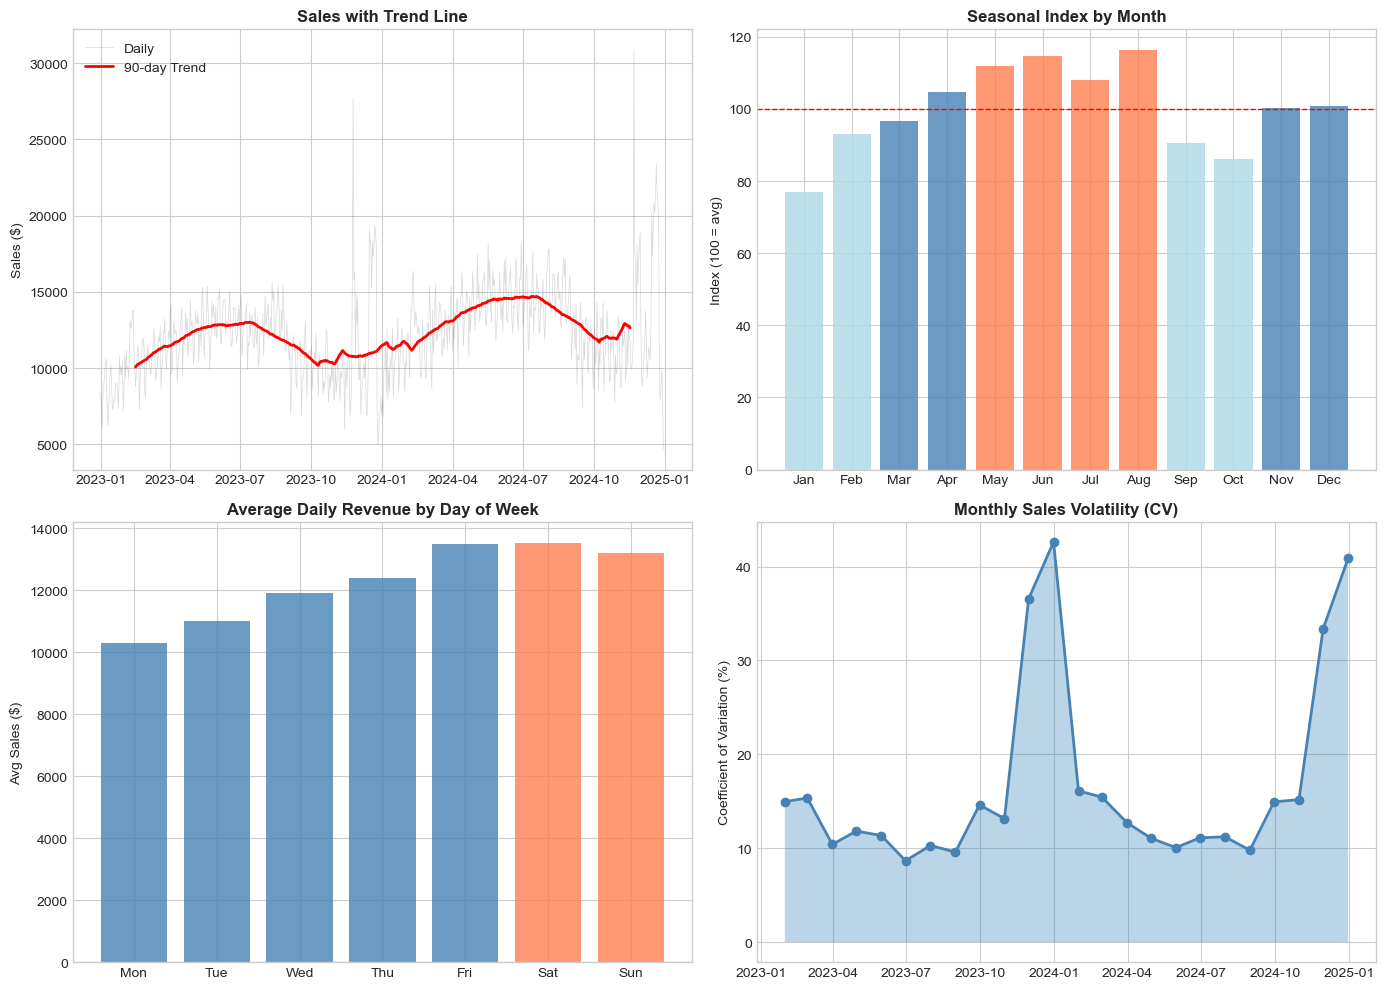

In [83]:
# Comprehensive visualization for the case study
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Full time series with trend
ax1 = axes[0, 0]
ax1.plot(df_trend.index, df_trend['sales'], linewidth=0.5, alpha=0.3, color='gray', label='Daily')
ax1.plot(df_trend.index, df_trend['trend'], linewidth=2, color='red', label='90-day Trend')
ax1.set_title('Sales with Trend Line', fontsize=12, fontweight='bold')
ax1.legend()
ax1.set_ylabel('Sales ($)')

# 2. Seasonal pattern
ax2 = axes[0, 1]
colors = ['coral' if idx > 105 else ('lightblue' if idx < 95 else 'steelblue') 
          for idx in seasonal_index.values]
bars = ax2.bar(seasonal_index.index, seasonal_index.values, color=colors, alpha=0.8)
ax2.axhline(y=100, color='red', linestyle='--', linewidth=1)
ax2.set_title('Seasonal Index by Month', fontsize=12, fontweight='bold')
ax2.set_ylabel('Index (100 = avg)')

# 3. Day of week pattern
ax3 = axes[1, 0]
colors = ['coral' if d in ['Saturday', 'Sunday'] else 'steelblue' for d in dow_order]
ax3.bar(range(7), dow_revenue['Avg Daily Revenue'].values, color=colors, alpha=0.8)
ax3.set_xticks(range(7))
ax3.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
ax3.set_title('Average Daily Revenue by Day of Week', fontsize=12, fontweight='bold')
ax3.set_ylabel('Avg Sales ($)')

# 4. Monthly volatility
ax4 = axes[1, 1]
ax4.plot(monthly_cv.index, monthly_cv.values, marker='o', linewidth=2, color='steelblue')
ax4.fill_between(monthly_cv.index, monthly_cv.values, alpha=0.3)
ax4.set_title('Monthly Sales Volatility (CV)', fontsize=12, fontweight='bold')
ax4.set_ylabel('Coefficient of Variation (%)')

plt.tight_layout()
plt.show()

---

# 9. Live Exercises with Solutions

Complete these exercises to practice time series concepts. Try them yourself first, then check the solutions!

## Exercise 1: Working with Dates (10 min)

**Tasks:**
1. Create a timestamp for your birthday in 2024
2. Calculate how many days until that date from January 1, 2024
3. What day of the week does it fall on?
4. Create a date range for the week of your birthday

In [84]:
# YOUR CODE HERE (Exercise 1)
# Example birthday: March 15

# 1. Create timestamp


# 2. Days from Jan 1


# 3. Day of week


# 4. Week range


In [85]:
# SOLUTION: Exercise 1
print("=== SOLUTION: Exercise 1 ===")

# 1. Create timestamp (using March 15 as example)
birthday = pd.Timestamp('2024-03-15')
print(f"1. Birthday: {birthday}")

# 2. Days from Jan 1
jan1 = pd.Timestamp('2024-01-01')
days_until = (birthday - jan1).days
print(f"2. Days from Jan 1: {days_until}")

# 3. Day of week
print(f"3. Day of week: {birthday.day_name()}")

# 4. Week range (birthday week: 3 days before to 3 days after)
week_start = birthday - pd.Timedelta(days=3)
week_end = birthday + pd.Timedelta(days=3)
birthday_week = pd.date_range(week_start, week_end)
print(f"4. Birthday week: {list(birthday_week.date)}")

=== SOLUTION: Exercise 1 ===
1. Birthday: 2024-03-15 00:00:00
2. Days from Jan 1: 74
3. Day of week: Friday
4. Birthday week: [datetime.date(2024, 3, 12), datetime.date(2024, 3, 13), datetime.date(2024, 3, 14), datetime.date(2024, 3, 15), datetime.date(2024, 3, 16), datetime.date(2024, 3, 17), datetime.date(2024, 3, 18)]


In [ ]:
# ═══ CHECKPOINT — "Exercise 2: Resampling Practice (15 min)" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import warnings
ts1 = pd.Timestamp('2024-01-15')
ts2 = pd.Timestamp('2024-01-15 09:30:00')
ts3 = pd.Timestamp(year=2024, month=1, day=15, hour=9, minute=30)
ts_now = pd.Timestamp.now()
ts = pd.Timestamp('2024-03-15 14:30:45')
dates = ['2024-01-15', '01/15/2024', '15-01-2024', 'January 15, 2024', '2024/01/15 09:30:00']
for date_str in dates:
    parsed = pd.to_datetime(date_str, dayfirst=False)
    print(f"'{date_str}' -> {parsed}")
custom_date = '15/Mar/2024:09:30:45'
parsed = pd.to_datetime(custom_date, format='%d/%b/%Y:%H:%M:%S')
log_date = '2024-01-15T09:30:45.123456'
parsed = pd.to_datetime(log_date)
delta1 = pd.Timedelta(days=5)
delta2 = pd.Timedelta(hours=3, minutes=30)
delta3 = pd.Timedelta('2 days 5 hours 30 minutes')
today = pd.Timestamp.now()
next_week = today + pd.Timedelta(weeks=1)
start = pd.Timestamp('2024-01-01')
end = pd.Timestamp('2024-03-15')
diff = end - start
dates_daily = pd.date_range(start='2024-01-01', end='2024-01-10')
hourly = pd.date_range('2024-01-01', periods=6, freq='H')
business = pd.date_range('2024-01-01', periods=6, freq='B')
weekly = pd.date_range('2024-01-01', periods=4, freq='W')
monthly = pd.date_range('2024-01-01', periods=4, freq='ME')
monthly_start = pd.date_range('2024-01-01', periods=4, freq='MS')
quarterly = pd.date_range('2024-01-01', periods=4, freq='QE')
dates = pd.date_range(start='2023-01-01', end='2024-12-31', freq='D')
n_days = len(dates)
def create_ecommerce_sales_data(dates):
    """
    Create realistic e-commerce sales data with multiple patterns.
    
    Components:
    1. Base sales level (~$10,000/day)
    2. Growth trend (15% annual growth)
    3. Yearly seasonality (holiday peaks)
    4. Weekly seasonality (weekend boost)
    5. Special events (Black Friday, Christmas)
    6. Random noise
    """
    n = len(dates)
    base = 10000
    daily_growth = 1.15 ** (1 / 365)
    trend = base * np.array([daily_growth ** i for i in range(n)])
    day_of_year = np.array([d.dayofyear for d in dates])
    yearly_seasonal = 0.2 * np.sin(2 * np.pi * (day_of_year - 60) / 365)
    day_of_week = np.array([d.dayofweek for d in dates])
    weekly_pattern = {0: -0.15, 1: -0.08, 2: -0.03, 3: 0.02, 4: 0.1, 5: 0.12, 6: 0.08}
    weekly_seasonal = np.array([weekly_pattern[d] for d in day_of_week])
    special_events = np.zeros(n)
    for i, date in enumerate(dates):
        if date.month == 11 and date.day >= 22 and (date.day <= 28) and (date.dayofweek == 4):
            special_events[i] = 1.5
        elif date.month == 11 and date.day >= 23 and (date.day <= 30):
            special_events[i] = 0.5
        elif date.month == 12 and date.day >= 15 and (date.day <= 24):
            special_events[i] = 0.7
        elif date.month == 12 and date.day >= 26:
            special_events[i] = -0.3
        elif date.month == 2 and date.day >= 7 and (date.day <= 14):
            special_events[i] = 0.25
        elif date.month == 8:
            special_events[i] = 0.15
    noise = np.random.normal(0, 0.08, n)
    sales = trend * (1 + yearly_seasonal + weekly_seasonal + special_events + noise)
    sales = np.maximum(sales, 0)
    return sales
sales = create_ecommerce_sales_data(dates)
df_sales = pd.DataFrame({'date': dates, 'sales': sales.round(2)})
df_sales['year'] = df_sales['date'].dt.year
df_sales['month'] = df_sales['date'].dt.month
df_sales['day_of_week'] = df_sales['date'].dt.dayofweek
df_sales['day_name'] = df_sales['date'].dt.day_name()
df_sales['is_weekend'] = df_sales['day_of_week'].isin([5, 6])
df_sales.to_csv('ecom_sales.csv', index=False)
df = pd.read_csv('../../00-data/ecom_sales.csv')
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
monthly = df_sales.groupby(df_sales['date'].dt.to_period('M'))['sales'].sum()
dow_sales = df_sales.groupby('day_name')['sales'].mean()
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_sales = dow_sales.reindex(dow_order)
colors = ['coral' if d in ['Saturday', 'Sunday'] else 'steelblue' for d in dow_order]
df_ts = df_sales.set_index('date')
june_2024 = df_ts.loc['2024-06']
year_2023 = df_ts.loc['2023']
q4_2024 = df_ts.loc['2024-10-01':'2024-12-31']
dec_2024 = df_ts.loc['2024-12']
high_sales = dec_2024[dec_2024['sales'] > 15000]
summer = df_sales[df_sales['date'].dt.month.isin([6, 7, 8])]
df_2024 = df_sales[df_sales['date'].dt.year == 2024].copy()
first_days = df_2024.groupby(df_2024['date'].dt.month).first()
last_days = df_2024.groupby(df_2024['date'].dt.month).last()
summary = pd.DataFrame({'First Day Sales': first_days['sales'].values, 'Last Day Sales': last_days['sales'].values}, index=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
df_ts = df_sales.set_index('date')
weekly_sales = df_ts['sales'].resample('W').sum()
monthly_stats = df_ts[['sales']].resample('ME').agg([('total', 'sum'), ('average', 'mean'), ('min', 'min'), ('max', 'max'), ('std', 'std')])
quarterly_sales = df_ts['sales'].resample('QE').agg(['sum', 'mean'])
quarterly_sales.columns = ['Total Sales', 'Daily Average']
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
weekly_avg = df_ts['sales'].resample('W').mean()
monthly_avg = df_ts['sales'].resample('ME').mean()
monthly_data = df_ts['sales'].resample('ME').sum()
daily_upsampled = monthly_data.resample('D').asfreq()
daily_ffill = monthly_data.resample('D').ffill()
daily_interp = monthly_data.resample('D').interpolate(method='linear')
df_rolling = df_ts[['sales']].copy()
df_rolling['MA_7'] = df_rolling['sales'].rolling(window=7).mean()
df_rolling['MA_30'] = df_rolling['sales'].rolling(window=30).mean()
df_rolling['MA_90'] = df_rolling['sales'].rolling(window=90).mean()
fig, ax = plt.subplots(figsize=(14, 6))
df_2024 = df_rolling.loc['2024']
df_rolling['rolling_std_30'] = df_rolling['sales'].rolling(window=30).std()
df_rolling['rolling_min_30'] = df_rolling['sales'].rolling(window=30).min()
df_rolling['rolling_max_30'] = df_rolling['sales'].rolling(window=30).max()
df_rolling['rolling_sum_7'] = df_rolling['sales'].rolling(window=7).sum()
df_rolling['EMA_30'] = df_rolling['sales'].ewm(span=30).mean()
fig, ax = plt.subplots(figsize=(14, 5))
df_q4 = df_rolling.loc['2024-10':'2024-12']
ma_right = df_ts['sales'].rolling(window=7).mean()
ma_centered = df_ts['sales'].rolling(window=7, center=True).mean()
sample = df_ts.loc['2024-01-01':'2024-01-15', ['sales']].copy()
sample['MA_right'] = ma_right
sample['MA_centered'] = ma_centered
dates_with_gaps = pd.date_range('2024-01-01', periods=30, freq='D')
values = np.random.randn(30) * 10 + 50
missing_indices = [5, 6, 12, 13, 14, 22]
values[missing_indices] = np.nan
df_gaps = pd.DataFrame({'value': values}, index=dates_with_gaps)
df_filled = df_gaps.copy()
df_filled['ffill'] = df_gaps['value'].ffill()
df_filled['bfill'] = df_gaps['value'].bfill()
df_filled['interpolate'] = df_gaps['value'].interpolate(method='linear')
df_filled['interpolate_time'] = df_gaps['value'].interpolate(method='time')
df_filled['mean_fill'] = df_gaps['value'].fillna(df_gaps['value'].mean())
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
methods = ['ffill', 'bfill', 'interpolate', 'mean_fill']
titles = ['Forward Fill', 'Backward Fill', 'Linear Interpolation', 'Mean Fill']
for ax, method, title in zip(axes.flat, methods, titles):
    ax.plot(df_filled.index, df_filled['value'], 'o', color='steelblue', markersize=8, label='Original')
    ax.plot(df_filled.index, df_filled[method], '-', color='coral', linewidth=2, label=title)
    mask = df_gaps['value'].isna()
    ax.scatter(df_filled.index[mask], df_filled[method][mask], color='red', s=100, zorder=5, marker='x', label='Filled')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)
ts_naive = pd.Timestamp('2024-06-15 14:30:00')
ts_nyc = ts_naive.tz_localize('America/New_York')
ts_london = ts_nyc.tz_convert('Europe/London')
ts_tokyo = ts_nyc.tz_convert('Asia/Tokyo')
ts_sydney = ts_nyc.tz_convert('Australia/Sydney')
dates = pd.date_range('2024-06-15', periods=5, freq='H', tz='America/New_York')
df_tz = pd.DataFrame({'NYC_time': dates, 'value': [100, 105, 103, 108, 110]})
df_tz['London_time'] = df_tz['NYC_time'].dt.tz_convert('Europe/London')
df_tz['Tokyo_time'] = df_tz['NYC_time'].dt.tz_convert('Asia/Tokyo')
import pytz
common_zones = ['UTC', 'America/New_York', 'America/Los_Angeles', 'America/Chicago', 'Europe/London', 'Europe/Paris', 'Asia/Tokyo', 'Asia/Shanghai', 'Australia/Sydney', 'Pacific/Auckland']
df = df_sales.set_index('date')
yearly_sales = df['sales'].resample('YE').sum()
yoy_growth = yearly_sales.pct_change() * 100
dow_revenue = df.groupby('day_name')['sales'].agg(['sum', 'mean', 'count'])
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_revenue = dow_revenue.reindex(dow_order)
dow_revenue.columns = ['Total Revenue', 'Avg Daily Revenue', 'Days']
dow_revenue['% of Total'] = dow_revenue['Total Revenue'] / dow_revenue['Total Revenue'].sum() * 100
best_day = dow_revenue['Avg Daily Revenue'].idxmax()
monthly_sales = df['sales'].resample('ME').sum()
avg_monthly = monthly_sales.mean()
monthly_index = (monthly_sales / avg_monthly * 100).round(1)
seasonal_pattern = df.groupby(df.index.month)['sales'].mean()
seasonal_pattern.index = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
avg_sales = seasonal_pattern.mean()
seasonal_index = (seasonal_pattern / avg_sales * 100).round(1)
for month, idx in seasonal_index.items():
    indicator = '📈' if idx > 105 else '📉' if idx < 95 else '➡️'
    print(f'  {month}: {idx} {indicator}')
volatility = df['sales'].rolling(window=30).std()
monthly_volatility = df['sales'].resample('ME').std()
monthly_mean = df['sales'].resample('ME').mean()
monthly_cv = (monthly_volatility / monthly_mean * 100).round(2)
df_trend = df[['sales']].copy()
df_trend['trend'] = df_trend['sales'].rolling(window=90, center=True).mean()
df_trend['detrended'] = df_trend['sales'] - df_trend['trend']
df_trend['seasonal'] = df_trend['sales'].rolling(window=7, center=True).mean() - df_trend['trend']
trend_start = df_trend['trend'].dropna().iloc[0]
trend_end = df_trend['trend'].dropna().iloc[-1]
trend_growth = (trend_end - trend_start) / trend_start * 100
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ax1 = axes[0, 0]
ax2 = axes[0, 1]
colors = ['coral' if idx > 105 else 'lightblue' if idx < 95 else 'steelblue' for idx in seasonal_index.values]
bars = ax2.bar(seasonal_index.index, seasonal_index.values, color=colors, alpha=0.8)
ax3 = axes[1, 0]
colors = ['coral' if d in ['Saturday', 'Sunday'] else 'steelblue' for d in dow_order]
ax4 = axes[1, 1]
birthday = pd.Timestamp('2024-03-15')
jan1 = pd.Timestamp('2024-01-01')
days_until = (birthday - jan1).days
week_start = birthday - pd.Timedelta(days=3)
week_end = birthday + pd.Timedelta(days=3)
birthday_week = pd.date_range(week_start, week_end)

print("Checkpoint restored. Ready for: Exercise 2: Resampling Practice (15 min)")

## Exercise 2: Resampling Practice (15 min)

Using our `df_sales` data:
1. Calculate the total sales for each quarter
2. Find the week with the highest total sales
3. Calculate the month-over-month percentage change
4. Find months where sales increased by more than 5% compared to the previous month

In [ ]:
# YOUR CODE HERE (Exercise 2)
df_ts = df_sales.set_index('date')

# 1. Quarterly totals


# 2. Best week


# 3. Month-over-month change


# 4. Months with >5% growth


In [ ]:
# SOLUTION: Exercise 2
print("=== SOLUTION: Exercise 2 ===")
df_ts = df_sales.set_index('date')

# 1. Quarterly totals
quarterly = df_ts['sales'].resample('QE').sum()
print("\n1. Quarterly Sales:")
print(quarterly.round(2))

# 2. Best week
weekly = df_ts['sales'].resample('W').sum()
best_week = weekly.idxmax()
best_week_sales = weekly.max()
print(f"\n2. Best week: {best_week.date()} with ${best_week_sales:,.2f}")

# 3. Month-over-month change
monthly = df_ts['sales'].resample('ME').sum()
mom_change = monthly.pct_change() * 100
print("\n3. Month-over-Month % Change:")
print(mom_change.round(2).head(12))

# 4. Months with >5% growth
growth_months = mom_change[mom_change > 5]
print(f"\n4. Months with >5% growth:")
print(growth_months.round(2))

## Exercise 3: Rolling Statistics (10 min)

Using `df_sales`:
1. Calculate a 14-day moving average
2. Calculate a 14-day rolling standard deviation
3. Create "Bollinger Bands" (MA ± 2 * std)
4. Find days where sales fell below the lower band (unusually low)

In [ ]:
# YOUR CODE HERE (Exercise 3)

# 1. 14-day MA


# 2. 14-day std


# 3. Bollinger Bands


# 4. Days below lower band


In [ ]:
# SOLUTION: Exercise 3
print("=== SOLUTION: Exercise 3 ===")

df_bb = df_ts[['sales']].copy()

# 1. 14-day MA
df_bb['MA_14'] = df_bb['sales'].rolling(window=14).mean()

# 2. 14-day std
df_bb['STD_14'] = df_bb['sales'].rolling(window=14).std()

# 3. Bollinger Bands
df_bb['upper_band'] = df_bb['MA_14'] + 2 * df_bb['STD_14']
df_bb['lower_band'] = df_bb['MA_14'] - 2 * df_bb['STD_14']

# 4. Days below lower band
below_band = df_bb[df_bb['sales'] < df_bb['lower_band']]
print(f"Days with unusually low sales: {len(below_band)}")
print("\nFirst 10 days below lower band:")
print(below_band[['sales', 'lower_band', 'MA_14']].head(10).round(2))

# Visualization
fig, ax = plt.subplots(figsize=(14, 5))
df_sample = df_bb.loc['2024-04':'2024-06']

ax.plot(df_sample.index, df_sample['sales'], linewidth=0.8, alpha=0.6, label='Daily Sales')
ax.plot(df_sample.index, df_sample['MA_14'], linewidth=2, color='orange', label='14-day MA')
ax.fill_between(df_sample.index, df_sample['lower_band'], df_sample['upper_band'], 
                alpha=0.2, color='gray', label='Bollinger Bands')

# Mark days below band
below_sample = below_band.loc['2024-04':'2024-06']
ax.scatter(below_sample.index, below_sample['sales'], color='red', s=50, zorder=5, label='Below Band')

ax.set_title('Sales with Bollinger Bands (Apr-Jun 2024)', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ═══ CHECKPOINT — "Exercise 4: Business Analysis Challenge (15 min)" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import warnings
ts1 = pd.Timestamp('2024-01-15')
ts2 = pd.Timestamp('2024-01-15 09:30:00')
ts3 = pd.Timestamp(year=2024, month=1, day=15, hour=9, minute=30)
ts_now = pd.Timestamp.now()
ts = pd.Timestamp('2024-03-15 14:30:45')
dates = ['2024-01-15', '01/15/2024', '15-01-2024', 'January 15, 2024', '2024/01/15 09:30:00']
for date_str in dates:
    parsed = pd.to_datetime(date_str, dayfirst=False)
    print(f"'{date_str}' -> {parsed}")
custom_date = '15/Mar/2024:09:30:45'
parsed = pd.to_datetime(custom_date, format='%d/%b/%Y:%H:%M:%S')
log_date = '2024-01-15T09:30:45.123456'
parsed = pd.to_datetime(log_date)
delta1 = pd.Timedelta(days=5)
delta2 = pd.Timedelta(hours=3, minutes=30)
delta3 = pd.Timedelta('2 days 5 hours 30 minutes')
today = pd.Timestamp.now()
next_week = today + pd.Timedelta(weeks=1)
start = pd.Timestamp('2024-01-01')
end = pd.Timestamp('2024-03-15')
diff = end - start
dates_daily = pd.date_range(start='2024-01-01', end='2024-01-10')
hourly = pd.date_range('2024-01-01', periods=6, freq='H')
business = pd.date_range('2024-01-01', periods=6, freq='B')
weekly = pd.date_range('2024-01-01', periods=4, freq='W')
monthly = pd.date_range('2024-01-01', periods=4, freq='ME')
monthly_start = pd.date_range('2024-01-01', periods=4, freq='MS')
quarterly = pd.date_range('2024-01-01', periods=4, freq='QE')
dates = pd.date_range(start='2023-01-01', end='2024-12-31', freq='D')
n_days = len(dates)
def create_ecommerce_sales_data(dates):
    """
    Create realistic e-commerce sales data with multiple patterns.
    
    Components:
    1. Base sales level (~$10,000/day)
    2. Growth trend (15% annual growth)
    3. Yearly seasonality (holiday peaks)
    4. Weekly seasonality (weekend boost)
    5. Special events (Black Friday, Christmas)
    6. Random noise
    """
    n = len(dates)
    base = 10000
    daily_growth = 1.15 ** (1 / 365)
    trend = base * np.array([daily_growth ** i for i in range(n)])
    day_of_year = np.array([d.dayofyear for d in dates])
    yearly_seasonal = 0.2 * np.sin(2 * np.pi * (day_of_year - 60) / 365)
    day_of_week = np.array([d.dayofweek for d in dates])
    weekly_pattern = {0: -0.15, 1: -0.08, 2: -0.03, 3: 0.02, 4: 0.1, 5: 0.12, 6: 0.08}
    weekly_seasonal = np.array([weekly_pattern[d] for d in day_of_week])
    special_events = np.zeros(n)
    for i, date in enumerate(dates):
        if date.month == 11 and date.day >= 22 and (date.day <= 28) and (date.dayofweek == 4):
            special_events[i] = 1.5
        elif date.month == 11 and date.day >= 23 and (date.day <= 30):
            special_events[i] = 0.5
        elif date.month == 12 and date.day >= 15 and (date.day <= 24):
            special_events[i] = 0.7
        elif date.month == 12 and date.day >= 26:
            special_events[i] = -0.3
        elif date.month == 2 and date.day >= 7 and (date.day <= 14):
            special_events[i] = 0.25
        elif date.month == 8:
            special_events[i] = 0.15
    noise = np.random.normal(0, 0.08, n)
    sales = trend * (1 + yearly_seasonal + weekly_seasonal + special_events + noise)
    sales = np.maximum(sales, 0)
    return sales
sales = create_ecommerce_sales_data(dates)
df_sales = pd.DataFrame({'date': dates, 'sales': sales.round(2)})
df_sales['year'] = df_sales['date'].dt.year
df_sales['month'] = df_sales['date'].dt.month
df_sales['day_of_week'] = df_sales['date'].dt.dayofweek
df_sales['day_name'] = df_sales['date'].dt.day_name()
df_sales['is_weekend'] = df_sales['day_of_week'].isin([5, 6])
df_sales.to_csv('ecom_sales.csv', index=False)
df = pd.read_csv('../../00-data/ecom_sales.csv')
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
monthly = df_sales.groupby(df_sales['date'].dt.to_period('M'))['sales'].sum()
dow_sales = df_sales.groupby('day_name')['sales'].mean()
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_sales = dow_sales.reindex(dow_order)
colors = ['coral' if d in ['Saturday', 'Sunday'] else 'steelblue' for d in dow_order]
df_ts = df_sales.set_index('date')
june_2024 = df_ts.loc['2024-06']
year_2023 = df_ts.loc['2023']
q4_2024 = df_ts.loc['2024-10-01':'2024-12-31']
dec_2024 = df_ts.loc['2024-12']
high_sales = dec_2024[dec_2024['sales'] > 15000]
summer = df_sales[df_sales['date'].dt.month.isin([6, 7, 8])]
df_2024 = df_sales[df_sales['date'].dt.year == 2024].copy()
first_days = df_2024.groupby(df_2024['date'].dt.month).first()
last_days = df_2024.groupby(df_2024['date'].dt.month).last()
summary = pd.DataFrame({'First Day Sales': first_days['sales'].values, 'Last Day Sales': last_days['sales'].values}, index=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
df_ts = df_sales.set_index('date')
weekly_sales = df_ts['sales'].resample('W').sum()
monthly_stats = df_ts[['sales']].resample('ME').agg([('total', 'sum'), ('average', 'mean'), ('min', 'min'), ('max', 'max'), ('std', 'std')])
quarterly_sales = df_ts['sales'].resample('QE').agg(['sum', 'mean'])
quarterly_sales.columns = ['Total Sales', 'Daily Average']
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
weekly_avg = df_ts['sales'].resample('W').mean()
monthly_avg = df_ts['sales'].resample('ME').mean()
monthly_data = df_ts['sales'].resample('ME').sum()
daily_upsampled = monthly_data.resample('D').asfreq()
daily_ffill = monthly_data.resample('D').ffill()
daily_interp = monthly_data.resample('D').interpolate(method='linear')
df_rolling = df_ts[['sales']].copy()
df_rolling['MA_7'] = df_rolling['sales'].rolling(window=7).mean()
df_rolling['MA_30'] = df_rolling['sales'].rolling(window=30).mean()
df_rolling['MA_90'] = df_rolling['sales'].rolling(window=90).mean()
fig, ax = plt.subplots(figsize=(14, 6))
df_2024 = df_rolling.loc['2024']
df_rolling['rolling_std_30'] = df_rolling['sales'].rolling(window=30).std()
df_rolling['rolling_min_30'] = df_rolling['sales'].rolling(window=30).min()
df_rolling['rolling_max_30'] = df_rolling['sales'].rolling(window=30).max()
df_rolling['rolling_sum_7'] = df_rolling['sales'].rolling(window=7).sum()
df_rolling['EMA_30'] = df_rolling['sales'].ewm(span=30).mean()
fig, ax = plt.subplots(figsize=(14, 5))
df_q4 = df_rolling.loc['2024-10':'2024-12']
ma_right = df_ts['sales'].rolling(window=7).mean()
ma_centered = df_ts['sales'].rolling(window=7, center=True).mean()
sample = df_ts.loc['2024-01-01':'2024-01-15', ['sales']].copy()
sample['MA_right'] = ma_right
sample['MA_centered'] = ma_centered
dates_with_gaps = pd.date_range('2024-01-01', periods=30, freq='D')
values = np.random.randn(30) * 10 + 50
missing_indices = [5, 6, 12, 13, 14, 22]
values[missing_indices] = np.nan
df_gaps = pd.DataFrame({'value': values}, index=dates_with_gaps)
df_filled = df_gaps.copy()
df_filled['ffill'] = df_gaps['value'].ffill()
df_filled['bfill'] = df_gaps['value'].bfill()
df_filled['interpolate'] = df_gaps['value'].interpolate(method='linear')
df_filled['interpolate_time'] = df_gaps['value'].interpolate(method='time')
df_filled['mean_fill'] = df_gaps['value'].fillna(df_gaps['value'].mean())
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
methods = ['ffill', 'bfill', 'interpolate', 'mean_fill']
titles = ['Forward Fill', 'Backward Fill', 'Linear Interpolation', 'Mean Fill']
for ax, method, title in zip(axes.flat, methods, titles):
    ax.plot(df_filled.index, df_filled['value'], 'o', color='steelblue', markersize=8, label='Original')
    ax.plot(df_filled.index, df_filled[method], '-', color='coral', linewidth=2, label=title)
    mask = df_gaps['value'].isna()
    ax.scatter(df_filled.index[mask], df_filled[method][mask], color='red', s=100, zorder=5, marker='x', label='Filled')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)
ts_naive = pd.Timestamp('2024-06-15 14:30:00')
ts_nyc = ts_naive.tz_localize('America/New_York')
ts_london = ts_nyc.tz_convert('Europe/London')
ts_tokyo = ts_nyc.tz_convert('Asia/Tokyo')
ts_sydney = ts_nyc.tz_convert('Australia/Sydney')
dates = pd.date_range('2024-06-15', periods=5, freq='H', tz='America/New_York')
df_tz = pd.DataFrame({'NYC_time': dates, 'value': [100, 105, 103, 108, 110]})
df_tz['London_time'] = df_tz['NYC_time'].dt.tz_convert('Europe/London')
df_tz['Tokyo_time'] = df_tz['NYC_time'].dt.tz_convert('Asia/Tokyo')
import pytz
common_zones = ['UTC', 'America/New_York', 'America/Los_Angeles', 'America/Chicago', 'Europe/London', 'Europe/Paris', 'Asia/Tokyo', 'Asia/Shanghai', 'Australia/Sydney', 'Pacific/Auckland']
df = df_sales.set_index('date')
yearly_sales = df['sales'].resample('YE').sum()
yoy_growth = yearly_sales.pct_change() * 100
dow_revenue = df.groupby('day_name')['sales'].agg(['sum', 'mean', 'count'])
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_revenue = dow_revenue.reindex(dow_order)
dow_revenue.columns = ['Total Revenue', 'Avg Daily Revenue', 'Days']
dow_revenue['% of Total'] = dow_revenue['Total Revenue'] / dow_revenue['Total Revenue'].sum() * 100
best_day = dow_revenue['Avg Daily Revenue'].idxmax()
monthly_sales = df['sales'].resample('ME').sum()
avg_monthly = monthly_sales.mean()
monthly_index = (monthly_sales / avg_monthly * 100).round(1)
seasonal_pattern = df.groupby(df.index.month)['sales'].mean()
seasonal_pattern.index = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
avg_sales = seasonal_pattern.mean()
seasonal_index = (seasonal_pattern / avg_sales * 100).round(1)
for month, idx in seasonal_index.items():
    indicator = '📈' if idx > 105 else '📉' if idx < 95 else '➡️'
    print(f'  {month}: {idx} {indicator}')
volatility = df['sales'].rolling(window=30).std()
monthly_volatility = df['sales'].resample('ME').std()
monthly_mean = df['sales'].resample('ME').mean()
monthly_cv = (monthly_volatility / monthly_mean * 100).round(2)
df_trend = df[['sales']].copy()
df_trend['trend'] = df_trend['sales'].rolling(window=90, center=True).mean()
df_trend['detrended'] = df_trend['sales'] - df_trend['trend']
df_trend['seasonal'] = df_trend['sales'].rolling(window=7, center=True).mean() - df_trend['trend']
trend_start = df_trend['trend'].dropna().iloc[0]
trend_end = df_trend['trend'].dropna().iloc[-1]
trend_growth = (trend_end - trend_start) / trend_start * 100
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ax1 = axes[0, 0]
ax2 = axes[0, 1]
colors = ['coral' if idx > 105 else 'lightblue' if idx < 95 else 'steelblue' for idx in seasonal_index.values]
bars = ax2.bar(seasonal_index.index, seasonal_index.values, color=colors, alpha=0.8)
ax3 = axes[1, 0]
colors = ['coral' if d in ['Saturday', 'Sunday'] else 'steelblue' for d in dow_order]
ax4 = axes[1, 1]
birthday = pd.Timestamp('2024-03-15')
jan1 = pd.Timestamp('2024-01-01')
days_until = (birthday - jan1).days
week_start = birthday - pd.Timedelta(days=3)
week_end = birthday + pd.Timedelta(days=3)
birthday_week = pd.date_range(week_start, week_end)
df_ts = df_sales.set_index('date')
df_ts = df_sales.set_index('date')
quarterly = df_ts['sales'].resample('QE').sum()
weekly = df_ts['sales'].resample('W').sum()
best_week = weekly.idxmax()
best_week_sales = weekly.max()
monthly = df_ts['sales'].resample('ME').sum()
mom_change = monthly.pct_change() * 100
growth_months = mom_change[mom_change > 5]
df_bb = df_ts[['sales']].copy()
df_bb['MA_14'] = df_bb['sales'].rolling(window=14).mean()
df_bb['STD_14'] = df_bb['sales'].rolling(window=14).std()
df_bb['upper_band'] = df_bb['MA_14'] + 2 * df_bb['STD_14']
df_bb['lower_band'] = df_bb['MA_14'] - 2 * df_bb['STD_14']
below_band = df_bb[df_bb['sales'] < df_bb['lower_band']]
fig, ax = plt.subplots(figsize=(14, 5))
df_sample = df_bb.loc['2024-04':'2024-06']
below_sample = below_band.loc['2024-04':'2024-06']

print("Checkpoint restored. Ready for: Exercise 4: Business Analysis Challenge (15 min)")

## Exercise 4: Business Analysis Challenge (15 min)

Your manager asks you to answer these questions about the sales data:

1. **Weekend Effect**: What is the average difference in sales between weekends and weekdays?
2. **Holiday Impact**: How much higher are November-December sales compared to the yearly average?
3. **Best vs Worst**: What is the ratio of the best month's sales to the worst month's sales?
4. **Growth Consistency**: In how many months did we see positive growth compared to the same month last year?

In [ ]:
# YOUR CODE HERE (Exercise 4)

# 1. Weekend effect


# 2. Holiday impact


# 3. Best vs worst month


# 4. Growth consistency


In [ ]:
# TODO: compute `weekend_avg`, `weekday_avg`, `weekend_effect` from `is_weekend`, `sales`, `month`
# Hint: .mean(), .sum(), monthly_totals.idxmax, monthly_totals.idxmin, pd.DataFrame
# Name your result: weekend_avg, weekday_avg, weekend_effect, holiday_months

---

# Summary and Key Takeaways

## What We Covered

| Topic | Key Functions/Concepts |
|-------|------------------------|
| **DateTime Basics** | `pd.Timestamp()`, `pd.to_datetime()`, `pd.Timedelta()` |
| **Date Ranges** | `pd.date_range()`, frequency codes (D, W, ME, QE, YE, H) |
| **Time Indexing** | `.set_index()`, partial string indexing (`df['2024-06']`) |
| **dt Accessor** | `.dt.year`, `.dt.month`, `.dt.dayofweek`, `.dt.day_name()` |
| **Resampling** | `.resample('W').sum()`, `.resample('ME').mean()` |
| **Rolling** | `.rolling(window=7).mean()`, `.ewm(span=30).mean()` |
| **Missing Data** | `.ffill()`, `.bfill()`, `.interpolate()` |
| **Time Zones** | `.tz_localize()`, `.tz_convert()` |

## Best Practices

1. **Always set datetime as index** for time series operations
2. **Use appropriate resampling** - don't aggregate too much (lose detail) or too little (too noisy)
3. **Choose filling methods wisely** - consider the nature of your data
4. **Document time zones** - always know if your data is UTC, local, or naive
5. **Visualize at multiple scales** - daily, weekly, monthly views reveal different patterns

## Next Steps

To deepen your time series skills:
- **Forecasting**: Learn `statsmodels` for ARIMA, exponential smoothing
- **Advanced decomposition**: Separate trend, seasonal, and residual components
- **Machine learning**: Apply sklearn or deep learning for time series prediction
- **Real-time data**: Work with streaming data using pandas with APIs

---

## Quick Reference: Frequency Codes

```
D   = Calendar day              B   = Business day
W   = Weekly                    ME  = Month end
MS  = Month start               QE  = Quarter end
QS  = Quarter start             YE  = Year end
YS  = Year start                H   = Hourly
T/min = Minute                  S   = Second
2H  = Every 2 hours             3D  = Every 3 days
```

---

**Congratulations!** You've completed the Pandas Time Series module. 🎉